# Experiment 8 — Exploratory ρ × data × capacity factorial

**Mode: exploratory. Measure everything, commit to no formula, no ε claim.**

This notebook does NOT pre-register a prediction and does NOT claim to measure ε.
It runs one grid on the Exp6/7 substrate and dumps every signal we have, so the
data can arbitrate which (if any) is clean. Decisions about what it *means* come
after we look at the dump — not before.

**The grid (per non-anchor language L_B, L_C):**
- ρ (anchor-overlap on conflicted lookups) ∈ {1.0, 0.85, 0.7, 0.5} — 1.0 is the zero-conflict control
- data budget ∈ {small, large}
- capacity d_model ∈ {8, 16, 32, 96}

**What gets dumped per cell (all seeds):**
- per-layer CKA, Procrustes residual, SVCCA mean (anchor vs each language), measured on matched leaves, mid layers *and* late layers separately
- task accuracy per language (on conflicted positions and overall)
- shared-model vs budget-matched-dedicated converged loss gap
- everything written to `exp8_results.json` + `exp8_raw.pt`, plus plots

**Guardrails carried over (learnings.md):** matched step budget (not epochs);
CKA on correct-in-both leaves only; shared-tree sampling never conditions on
language; mid-vs-late layers separated so late-layer output-routing separation
(the CLT 'decoding' region) can't masquerade as the signal.

Set the GPU id in the device cell (currently `cuda:2`).

## 0. Device setup

In [1]:
import os, json, time, math, random
from collections import defaultdict
import torch
import torch.nn as nn
import torch.nn.functional as F

GPU_ID = 0                        # <-- set your GPU here
DEVICE = torch.device(f"cuda:{GPU_ID}" if torch.cuda.is_available() else "cpu")
print(f"using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  {torch.cuda.get_device_name(GPU_ID)}")

from contextlib import nullcontext
def autocast_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16) if DEVICE.type == "cuda" else nullcontext()

torch.manual_seed(0)
random.seed(0)

using device: cuda:0
  NVIDIA H200 NVL


## 1. Config (reused from Exp6/7, plus ρ-conflict knob)

In [2]:
# ---- base PCFG (unchanged from Exp6/7) ----
LEVELS = 6
NT_SIZE = 4
TERM_SIZE = 4
MIN_DEGREE = 2
MAX_DEGREE = 4
RULE_LEN_CHOICES = [2, 3]

# three languages by linearization (word-order) divergence, exactly as Exp6
LANGS = {
    "L_A": set(),                      # identity (anchor)
    "L_B": {4, 5},                     # partial reversal
    "L_C": set(range(1, LEVELS + 1)),  # full reversal
}
LANG_NAMES = list(LANGS.keys())
ANCHOR = "L_A"
NONANCHOR = ["L_B", "L_C"]

BOS_OFFSET = TERM_SIZE
BOS = {name: BOS_OFFSET + i for i, name in enumerate(LANG_NAMES)}

# ---- ρ-conflict knob (the Exp4 mechanism, the one §3 says actually works) ----
# A fraction (1-ρ) of CONFLICT terminal slots get remapped per-language to a
# different terminal than the anchor would use. ρ=1.0 => no conflict (pure Exp6).
# This is a value conflict at shared tree positions: same tree slot, different
# required token for L_B/L_C vs the anchor. Deliberately simple and clean.
N_CONFLICT_SLOTS = 8        # how many distinct (level,idx)->terminal slots are conflict-eligible
CONFLICT_TERMS = list(range(TERM_SIZE))

RHO_SWEEP   = [1.00, 0.50]          # SMOKE. full grid: [1.00, 0.85, 0.70, 0.50]
DATA_SWEEP  = {"large": 12000}       # SMOKE. full grid: {"small": 1500, "large": 12000}
ANCHOR_TREES = 12000                            # anchor always large
D_LIST = [8, 96]                     # SMOKE. full grid: [8, 16, 32, 96]
SEEDS = [0]                          # SMOKE. full grid: [0, 7, 13]

N_HEAD = 4
N_LAYER = 8
SEQ_LEN = 512          # must exceed longest tree (~400 leaves) so every tree fits one window
STEP_BUDGET = 8000          # fixed, matched across ALL cells (convergence-matched, not epoch-matched)
BATCH_SIZE = 32
LR = 3e-3

VOCAB_SIZE = TERM_SIZE + len(LANG_NAMES)

MID_LAYERS  = [3, 4, 5]     # 'shared space' region to watch
LATE_LAYERS = [6, 7]        # 'decoding' region (expected to separate for everyone)
PROBE_LAYERS = MID_LAYERS + LATE_LAYERS

for d in D_LIST:
    assert d % N_HEAD == 0 and (d // N_HEAD) % 2 == 0, f"d={d}: head_dim must be even for rotary"
print("config OK. vocab:", VOCAB_SIZE, "| cells per language:",
      len(RHO_SWEEP)*len(DATA_SWEEP)*len(D_LIST)*len(SEEDS))

config OK. vocab: 7 | cells per language: 4


## 2. Grammar builder, sampler, linearizer, conflict map (reused + ρ addition)

In [3]:
def build_grammar(seed):
    rng = random.Random(seed)
    symbols_by_level = {1: [(1, 0)]}
    for l in range(2, LEVELS + 1):
        symbols_by_level[l] = [(l, i) for i in range(NT_SIZE)]
    terminals = list(range(TERM_SIZE))
    rules = defaultdict(list)
    for l in range(1, LEVELS + 1):
        child_level = l + 1
        child_symbols = terminals if child_level == LEVELS + 1 else symbols_by_level[child_level]
        for sym in symbols_by_level[l]:
            degree = rng.randint(MIN_DEGREE, MAX_DEGREE)
            seen = set()
            tries = 0
            while len(rules[sym]) < degree and tries < 200:
                tries += 1
                rule_len = rng.choice(RULE_LEN_CHOICES)
                rhs = tuple(rng.choice(child_symbols) for _ in range(rule_len))
                if rhs in seen: continue
                seen.add(rhs)
                rules[sym].append(rhs)
    return rules, symbols_by_level

def sample_tree(rules, rng, symbol=(1, 0), level=1):
    """Language-AGNOSTIC tree sampler. Never conditions on language (Anwoy's rule)."""
    rhs = rng.choice(rules[symbol])
    children = []
    for child_sym in rhs:
        if level == LEVELS:
            children.append(child_sym)
        else:
            children.append(sample_tree(rules, rng, symbol=child_sym, level=level + 1))
    return (symbol, children)

def build_conflict_map(rules, seed):
    """Pick N_CONFLICT_SLOTS leaf-producing contexts to be conflict-eligible, and
    for each non-anchor language assign an alternative terminal. Returns, for each
    language, a dict parent_sym -> {original_term: replacement_term} applied with
    prob (1-ρ) at generation time. Anchor = identity always."""
    rng = random.Random(seed + 101)
    # eligible parents: level-LEVELS NT symbols (those that emit terminals)
    leaf_parents = [(LEVELS, i) for i in range(NT_SIZE)]
    cmap = {lang: defaultdict(dict) for lang in LANG_NAMES}
    slots = 0
    for parent in leaf_parents:
        for orig in range(TERM_SIZE):
            if slots >= N_CONFLICT_SLOTS: break
            for lang in NONANCHOR:
                alt = rng.choice([t for t in CONFLICT_TERMS if t != orig])
                cmap[lang][parent][orig] = alt
            slots += 1
    return cmap

def linearize_with_conflict(node, reverse_levels, cmap_lang, rho, rng, parent=None):
    """Linearize under word-order divergence (reverse_levels) AND apply value
    conflicts: at a conflict-eligible (parent, terminal), with prob (1-rho)
    swap to the language's alternative terminal. ρ=1 => no swaps (pure Exp6)."""
    if isinstance(node, int):
        term = node
        if parent in cmap_lang and term in cmap_lang[parent] and rng.random() > rho:
            term = cmap_lang[parent][term]
        return [term]
    (level, idx), children = node
    order = list(reversed(children)) if level in reverse_levels else children
    tokens = []
    for c in order:
        tokens.extend(linearize_with_conflict(c, reverse_levels, cmap_lang, rho, rng, parent=(level, idx)))
    return tokens

print("grammar/sampler/conflict-map ready")

grammar/sampler/conflict-map ready


## 3. Model — TinyRotaryGPT (unchanged from Exp6/7)

In [4]:
def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)
def apply_rotary(q, k, cos, sin):
    return (q * cos) + (rotate_half(q) * sin), (k * cos) + (rotate_half(k) * sin)

class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=1024, base=10000):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.einsum("i,j->ij", t, inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin", emb.sin()[None, None, :, :], persistent=False)
    def forward(self, seq_len):
        return self.cos[:, :, :seq_len, :], self.sin[:, :, :seq_len, :]

class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, max_seq_len):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head; self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.rotary = RotaryEmbedding(self.head_dim, max_seq_len)
    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_head, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        cos, sin = self.rotary(T)
        q, k = apply_rotary(q, k, cos.to(x.dtype), sin.to(x.dtype))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(y)

class Block(nn.Module):
    def __init__(self, n_embd, n_head, max_seq_len):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, max_seq_len)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(), nn.Linear(4*n_embd, n_embd))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class TinyRotaryGPT(nn.Module):
    def __init__(self, vocab_size, n_embd, n_layer=8, n_head=4, max_seq_len=512):
        super().__init__()
        assert n_embd % n_head == 0 and (n_embd // n_head) % 2 == 0
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, max_seq_len) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        for blk in self.blocks: x = blk(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

def count_params(d, n_layer=N_LAYER, n_head=N_HEAD, vocab_size=VOCAB_SIZE, seq_len=SEQ_LEN):
    m = TinyRotaryGPT(vocab_size, n_embd=d, n_layer=n_layer, n_head=n_head, max_seq_len=seq_len + 1)
    return sum(p.numel() for p in m.parameters())

torch.manual_seed(0)
_m = TinyRotaryGPT(VOCAB_SIZE, n_embd=8, n_layer=2, n_head=2, max_seq_len=64).to(DEVICE)
_idx = torch.randint(0, VOCAB_SIZE, (4, 32), device=DEVICE)
print("forward OK:", _m(_idx, _idx)[0].shape)

forward OK: torch.Size([4, 32, 7])


## 4. Data generation (shared-tree, divergent-lin, ρ-conflict)

One shared bank of trees is sampled **once per seed, language-agnostically**.
Every language linearizes the SAME trees — so any representation difference is
attributable to linearization + conflict, never to a different tree distribution.
Data budget controls how many of the shared trees each non-anchor language
actually gets to train on (the funding knob).

In [5]:
def make_tree_bank(rules, n_trees, seed):
    rng = random.Random(seed + 555)
    return [sample_tree(rules, rng) for _ in range(n_trees)]

def pack_language(tree_bank, lang_name, cmap, rho, seed, n_trees):
    """Linearize the first n_trees of the shared bank under one language, with
    conflict applied. Returns packed (n_chunks, seq_len+1) training tensor AND a
    per-leaf eval pack (leaf_id grid + positions) for the matched-activation probe."""
    rng = random.Random(seed + LANG_NAMES.index(lang_name) * 10007)
    revset = LANGS[lang_name]
    cmap_lang = cmap[lang_name]
    stream = []
    for tree in tree_bank[:n_trees]:
        stream.append(BOS[lang_name])
        stream.extend(linearize_with_conflict(tree, revset, cmap_lang, rho, rng))
    stream = torch.tensor(stream, dtype=torch.long)
    n_chunks = len(stream) // (SEQ_LEN + 1)
    packed = stream[: n_chunks * (SEQ_LEN + 1)].view(n_chunks, SEQ_LEN + 1)
    return packed

def make_eval_pack(tree_bank, lang_name, cmap, rho, seed, n_eval=300):
    """Parallel eval set: the SAME n_eval trees across languages, one tree per row,
    padded. Records leaf_id per position so we can match leaves across languages.
    Conflict applied deterministically (rho) so conflicted positions are known."""
    rng = random.Random(seed + 9999)
    revset = LANGS[lang_name]
    cmap_lang = cmap[lang_name]
    rows, leaf_rows = [], []
    # assign a stable leaf_id by DFS order on the shared tree (language-agnostic id)
    def dfs_leaves(node, acc):
        if isinstance(node, int): acc.append(node); return
        (_lv, _ix), ch = node
        for c in ch: dfs_leaves(c, acc)
    for tree in tree_bank[:n_eval]:
        # canonical leaf order (anchor identity order) gives each leaf a stable id
        canon = []
        dfs_leaves(tree, canon)
        leaf_id_of = {i: i for i in range(len(canon))}
        # now linearize under this language, tracking which canonical leaf each emitted token is
        # (we re-walk in this language's order and emit the canonical index)
        order_ids = []
        def walk(node, lv_rev):
            if isinstance(node, int):
                order_ids.append(len(order_ids_canon_counter))
                return
        # simpler: reproduce linearization order and pair with canonical ids via a counter on canonical DFS
        # Build mapping by walking both orders. We attach ids by object identity of leaf slots.
        # Since leaves are plain ints (not unique objects), re-walk with an index pointer per canonical slot.
        toks, ids = _linearize_with_ids(tree, revset, cmap_lang, rho, rng)
        seq = [BOS[lang_name]] + toks
        lids = [-1] + ids
        rows.append(seq); leaf_rows.append(lids)
    maxlen = max(len(r) for r in rows)
    assert maxlen <= SEQ_LEN + 1, f"eval tree of {maxlen} tokens exceeds context {SEQ_LEN+1}; raise SEQ_LEN"
    idx = torch.full((len(rows), maxlen), 0, dtype=torch.long)
    leaf = torch.full((len(rows), maxlen), -1, dtype=torch.long)
    for t,(r,l) in enumerate(zip(rows, leaf_rows)):
        idx[t,:len(r)] = torch.tensor(r); leaf[t,:len(l)] = torch.tensor(l)
    return {"idx": idx, "leaf_id": leaf}

def _linearize_with_ids(node, reverse_levels, cmap_lang, rho, rng, counter=None, parent=None):
    """Like linearize_with_conflict but also returns a canonical leaf id per token.
    Canonical id = order of appearance in ANCHOR (identity, no-reverse) DFS. We get
    that by assigning ids during a parallel identity-order DFS."""
    # First pass: identity DFS to assign canonical ids to each physical leaf slot.
    # We tag each leaf slot with an id by walking identity order once.
    if counter is None:
        # build id map keyed by path to leaf
        idmap = {}
        c = [0]
        def idwalk(n, path):
            if isinstance(n, int):
                idmap[tuple(path)] = c[0]; c[0]+=1; return
            (_lv,_ix), ch = n
            for k,ck in enumerate(ch): idwalk(ck, path+[k])
        idwalk(node, [])
        toks, ids = [], []
        def emit(n, path):
            if isinstance(n, int):
                term = n
                p = None
                toks.append(term); ids.append(idmap[tuple(path)]); return
            (level, ix), ch = n
            order = list(range(len(ch)))
            if level in reverse_levels: order = list(reversed(order))
            for k in order:
                child = ch[k]
                if isinstance(child, int):
                    term = child
                    if (level,ix) in cmap_lang and term in cmap_lang[(level,ix)] and rng.random() > rho:
                        term = cmap_lang[(level,ix)][term]
                    toks.append(term); ids.append(idmap[tuple(path+[k])])
                else:
                    emit(child, path+[k])
        emit(node, [])
        return toks, ids

print("data generation ready")

data generation ready


## 5. Representation metrics (reused verbatim from Exp6)

In [6]:
def _avg(xs):
    xs = [x for x in xs if x is not None]
    return sum(xs)/len(xs) if xs else None

@torch.no_grad()
def extract_hidden_states(model, idx_tensor, layers=PROBE_LAYERS, batch_size=64, device=DEVICE):
    model.eval()
    activations = {l: [] for l in layers}
    def make_hook(l):
        def hook(module, inp, out): activations[l].append(out.detach().float().cpu())
        return hook
    handles = [model.blocks[l].register_forward_hook(make_hook(l)) for l in layers]
    try:
        for i in range(0, idx_tensor.shape[0], batch_size):
            batch = idx_tensor[i:i+batch_size].to(device)
            with autocast_ctx(): _ = model(batch)
    finally:
        for h in handles: h.remove()
    return {l: torch.cat(activations[l], dim=0) for l in layers}

def _positions_for_leaves(pack):
    leaf = pack["leaf_id"]
    n_trees = leaf.shape[0]
    max_lid = int(leaf.max().item()) + 1
    pos = -torch.ones(n_trees, max_lid, dtype=torch.long)
    t_idx, p_idx = (leaf >= 0).nonzero(as_tuple=True)
    pos[t_idx, leaf[t_idx, p_idx]] = p_idx
    return pos

@torch.no_grad()
def collect_matched(H_A, pack_A, H_B, pack_B, layer, device="cpu"):
    Ha = H_A[layer].to(device).float(); Hb = H_B[layer].to(device).float()
    Ha = Ha - Ha.mean(dim=0, keepdim=True); Hb = Hb - Hb.mean(dim=0, keepdim=True)
    pos_A = _positions_for_leaves(pack_A).to(device)
    pos_B = _positions_for_leaves(pack_B).to(device)
    n_trees = min(pos_A.shape[0], pos_B.shape[0])
    max_lid = min(pos_A.shape[1], pos_B.shape[1])
    pos_A = pos_A[:n_trees,:max_lid]; pos_B = pos_B[:n_trees,:max_lid]
    valid = (pos_A >= 0) & (pos_B >= 0)
    oa, ob = [], []
    for t in range(n_trees):
        lids = valid[t].nonzero(as_tuple=True)[0]
        if lids.numel()==0: continue
        oa.append(Ha[t, pos_A[t,lids]]); ob.append(Hb[t, pos_B[t,lids]])
    if not oa: return None, None
    return torch.cat(oa,0), torch.cat(ob,0)

def cka(X, Y):
    Xc = X - X.mean(0, keepdim=True); Yc = Y - Y.mean(0, keepdim=True)
    return ((Xc.T @ Yc).norm()**2 / ((Xc.T @ Xc).norm() * (Yc.T @ Yc).norm())).item()

def procrustes_residual(X, Y, eps=1e-8):
    M = Y.T @ X
    U,_,Vt = torch.linalg.svd(M); R = U @ Vt
    return ((X - Y @ R).norm() / (X.norm()+eps)).item()

def svcca_mean(X, Y, k_svd=None, eps=1e-6):
    n = X.shape[0]
    if k_svd is not None:
        Ua,Sa,_ = torch.linalg.svd(X, full_matrices=False)
        Uc,Sc,_ = torch.linalg.svd(Y, full_matrices=False)
        X = Ua[:,:k_svd]*Sa[:k_svd]; Y = Uc[:,:k_svd]*Sc[:k_svd]
    Cxx = X.T@X/(n-1) + eps*torch.eye(X.shape[1]); Cyy = Y.T@Y/(n-1) + eps*torch.eye(Y.shape[1])
    Cxy = X.T@Y/(n-1)
    Lx = torch.linalg.cholesky(Cxx); Ly = torch.linalg.cholesky(Cyy)
    T = torch.linalg.solve_triangular(Lx, Cxy, upper=False)
    T = torch.linalg.solve_triangular(Ly, T.T, upper=False).T
    _,S,_ = torch.linalg.svd(T)
    return S.clamp(0,1).mean().item()

print("metrics ready")

metrics ready


## 6. Train + eval one model (fixed step budget = convergence-matched)

In [7]:
def train_model(packed_by_lang, mix, d_model, seed, step_budget=STEP_BUDGET):
    """Train one SHARED model on a language mixture. packed_by_lang: {lang: tensor}.
    mix: {lang: prob}. Fixed step budget for all cells."""
    torch.manual_seed(seed)
    model = TinyRotaryGPT(VOCAB_SIZE, n_embd=d_model, n_layer=N_LAYER,
                          n_head=N_HEAD, max_seq_len=SEQ_LEN+1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    langs = list(packed_by_lang.keys())
    data = {l: packed_by_lang[l].to(DEVICE) for l in langs}
    probs = torch.tensor([mix[l] for l in langs])
    losses = []
    for step in range(step_budget):
        # sample a language per-batch by mix, then rows within it
        li = torch.multinomial(probs, 1).item(); lang = langs[li]
        n = data[lang].shape[0]
        if n == 0: continue
        ridx = torch.randint(0, n, (BATCH_SIZE,), device=DEVICE)
        batch = data[lang][ridx]
        x, y = batch[:, :-1], batch[:, 1:]
        with autocast_ctx(): _, loss = model(x, y)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return model, losses

@torch.no_grad()
def next_token_accuracy(model, packed, max_batches=50):
    """Overall next-token accuracy on packed sequences (teacher-forced)."""
    model.eval(); correct=0; total=0
    data = packed.to(DEVICE)
    for i in range(0, min(data.shape[0], max_batches*BATCH_SIZE), BATCH_SIZE):
        batch = data[i:i+BATCH_SIZE]
        x,y = batch[:,:-1], batch[:,1:]
        with autocast_ctx(): logits,_ = model(x,y)
        pred = logits.argmax(-1)
        correct += (pred==y).sum().item(); total += y.numel()
    return correct/max(total,1)

print("train/eval ready")

train/eval ready


## 7. Budget-matched dedicated baseline (reused logic from Exp6b)

For the shared-vs-dedicated loss gap: a dedicated model gets width d' such that
K=3 copies at d' ≈ params of the shared model at d. Each language trained alone
at d', same step budget. This is the §2 [A]-level comparison, kept honest with
budget-matching so a gap can't be 'dedicated just had more params'.

In [8]:
def find_budget_matched_width(d_shared, K=3, n_head=N_HEAD):
    target = count_params(d_shared)
    unit = 2*n_head
    cands = list(range(unit, d_shared+1, unit))
    best = min(cands, key=lambda dp: abs(K*count_params(dp) - target))
    return best, K*count_params(best)/target

BM_WIDTHS = {d: find_budget_matched_width(d)[0] for d in D_LIST}
print("budget-matched widths:", BM_WIDTHS)

def train_dedicated_loss(packed_by_lang, d_model, seed, step_budget=STEP_BUDGET):
    """Train one dedicated model per language at d', return mean tail loss across langs."""
    dprime = BM_WIDTHS[d_model]
    tail_losses = []
    for lang, packed in packed_by_lang.items():
        if packed.shape[0]==0: continue
        torch.manual_seed(seed + LANG_NAMES.index(lang) * 1009)
        model = TinyRotaryGPT(VOCAB_SIZE, n_embd=dprime, n_layer=N_LAYER,
                              n_head=N_HEAD, max_seq_len=SEQ_LEN+1).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=LR)
        data = packed.to(DEVICE); n = data.shape[0]; losses=[]
        for step in range(step_budget):
            ridx = torch.randint(0,n,(BATCH_SIZE,),device=DEVICE)
            batch = data[ridx]; x,y = batch[:,:-1], batch[:,1:]
            with autocast_ctx(): _,loss = model(x,y)
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        tail_losses.append(sum(losses[-500:])/len(losses[-500:]))
    return sum(tail_losses)/max(len(tail_losses),1)

print("dedicated baseline ready")

budget-matched widths: {8: 8, 96: 56}
dedicated baseline ready


## 8. THE SWEEP — runs the full grid, dumps everything

Loop order: seed → ρ → data → capacity. For each cell: build shared tree bank,
pack all three languages, train shared model, measure per-layer CKA/Procrustes/
SVCCA (anchor vs each non-anchor, mid + late), accuracy, and (once per
ρ×data×capacity) the dedicated loss gap. All rows appended to `RESULTS`.

Estimated: 3 seeds × 4 ρ × 2 data × 4 d = 96 shared models + 96 dedicated-triples.
On an H200 at this toy scale this is roughly a few hours. Checkpoints to disk
every cell so a crash doesn't lose progress.

In [9]:
RUN_DEDICATED = False   # SMOKE: skip dedicated baseline (set True for full grid)
RESULTS = []
RAW_ACTS = {}   # optional: keep a few activation snapshots for later deep-dives
CKPT = "exp8_results.json"

def already_done(seed, rho, data_key, d):
    return any(r["seed"]==seed and r["rho"]==rho and r["data"]==data_key and r["d"]==d
               and r["lang"]=="L_B" for r in RESULTS)

if os.path.exists(CKPT):
    RESULTS = json.load(open(CKPT))
    print(f"resumed {len(RESULTS)} rows from {CKPT}")

t_start = time.time()
for seed in SEEDS:
    rules, _ = build_grammar(seed)
    cmap = build_conflict_map(rules, seed)
    tree_bank = make_tree_bank(rules, ANCHOR_TREES, seed)
    eval_banks = {}  # per rho, per lang eval pack (parallel trees)
    for rho in RHO_SWEEP:
        # eval packs are small and rho-dependent (conflict applied); build once per (seed,rho)
        eval_banks[rho] = {lang: make_eval_pack(tree_bank, lang, cmap, rho, seed, n_eval=300)
                           for lang in LANG_NAMES}
        for data_key, n_na in DATA_SWEEP.items():
            # pack languages: anchor large, non-anchors at n_na
            packed = {ANCHOR: pack_language(tree_bank, ANCHOR, cmap, 1.0, seed, ANCHOR_TREES)}
            for lang in NONANCHOR:
                packed[lang] = pack_language(tree_bank, lang, cmap, rho, seed, n_na)
            mix = {ANCHOR:0.70, "L_B":0.15, "L_C":0.15}
            for d in D_LIST:
                if already_done(seed, rho, data_key, d):
                    continue
                tc = time.time()
                model, losses = train_model(packed, mix, d, seed)
                tail = sum(losses[-500:])/len(losses[-500:])
                # dedicated gap (once per cell, uses same packed data)
                ded_loss = train_dedicated_loss(packed, d, seed) if RUN_DEDICATED else float("nan")
                # representation probe: extract anchor + each non-anchor on parallel eval trees
                H = {lang: extract_hidden_states(model, eval_banks[rho][lang]["idx"])
                     for lang in LANG_NAMES}
                for lang in NONANCHOR:
                    row = {"seed":seed,"rho":rho,"data":data_key,"n_na":n_na,"d":d,"lang":lang,
                           "shared_tail_loss":tail,"dedicated_tail_loss":ded_loss,
                           "loss_gap":tail-ded_loss,
                           "acc_anchor":next_token_accuracy(model, packed[ANCHOR]),
                           "acc_lang":next_token_accuracy(model, packed[lang])}
                    for layer in PROBE_LAYERS:
                        Xa, Xb = collect_matched(H[ANCHOR], eval_banks[rho][ANCHOR],
                                                 H[lang], eval_banks[rho][lang], layer)
                        if Xa is None:
                            row[f"cka_L{layer}"]=None; row[f"proc_L{layer}"]=None; row[f"svcca_L{layer}"]=None
                            continue
                        # subsample for SVD tractability
                        if Xa.shape[0] > 4000:
                            sel = torch.randperm(Xa.shape[0])[:4000]; Xa=Xa[sel]; Xb=Xb[sel]
                        row[f"cka_L{layer}"]   = cka(Xa, Xb)
                        row[f"proc_L{layer}"]  = procrustes_residual(Xa, Xb)
                        row[f"svcca_L{layer}"] = svcca_mean(Xa, Xb, k_svd=min(Xa.shape[1], d, 32))
                    # convenience aggregates
                    row["cka_mid"]  = _avg([row.get(f"cka_L{l}") for l in MID_LAYERS])
                    row["cka_late"] = _avg([row.get(f"cka_L{l}") for l in LATE_LAYERS])
                    row["proc_mid"] = _avg([row.get(f"proc_L{l}") for l in MID_LAYERS])
                    row["proc_late"]= _avg([row.get(f"proc_L{l}") for l in LATE_LAYERS])
                    RESULTS.append(row)
                json.dump(RESULTS, open(CKPT,"w"), indent=1)
                el = time.time()-tc
                print(f"seed{seed} rho{rho} {data_key} d{d}: tail={tail:.3f} ded={ded_loss:.3f} "
                      f"gap={tail-ded_loss:+.3f} | L_B cka_mid={RESULTS[-2]['cka_mid']} "
                      f"cka_late={RESULTS[-2]['cka_late']} ({el:.0f}s)")

print(f"\nDONE. {len(RESULTS)} rows in {(time.time()-t_start)/60:.1f} min -> {CKPT}")

seed0 rho1.0 large d8: tail=0.958 ded=nan gap=+nan | L_B cka_mid=0.6740927298863729 cka_late=0.6837246119976044 (66s)
seed0 rho1.0 large d96: tail=0.824 ded=nan gap=+nan | L_B cka_mid=0.6722243825594584 cka_late=0.490324929356575 (71s)
seed0 rho0.5 large d8: tail=1.084 ded=nan gap=+nan | L_B cka_mid=0.39954103032747906 cka_late=0.24211826920509338 (71s)
seed0 rho0.5 large d96: tail=0.917 ded=nan gap=+nan | L_B cka_mid=0.36461501320203143 cka_late=0.220798097550869 (70s)

DONE. 8 rows in 4.8 min -> exp8_results.json


## 9. Read the dump — the four things to look at

No formula, no fit. Just plot the raw signals and see if anything is clean.

1. **ρ=1 control**: does mid-layer CKA stay HIGH (shared) across all d and data?
   If yes → the Exp6 ghost was late-layer. If no → the ghost is real, stop and diagnose.
2. **Capacity gate**: at ρ<1, does mid-layer separation only appear above some d?
3. **ρ × data interaction**: at fixed d, does separation need BOTH low ρ AND large data?
4. **Mid vs late**: is late-layer separation present for everyone regardless (CLT prediction)?

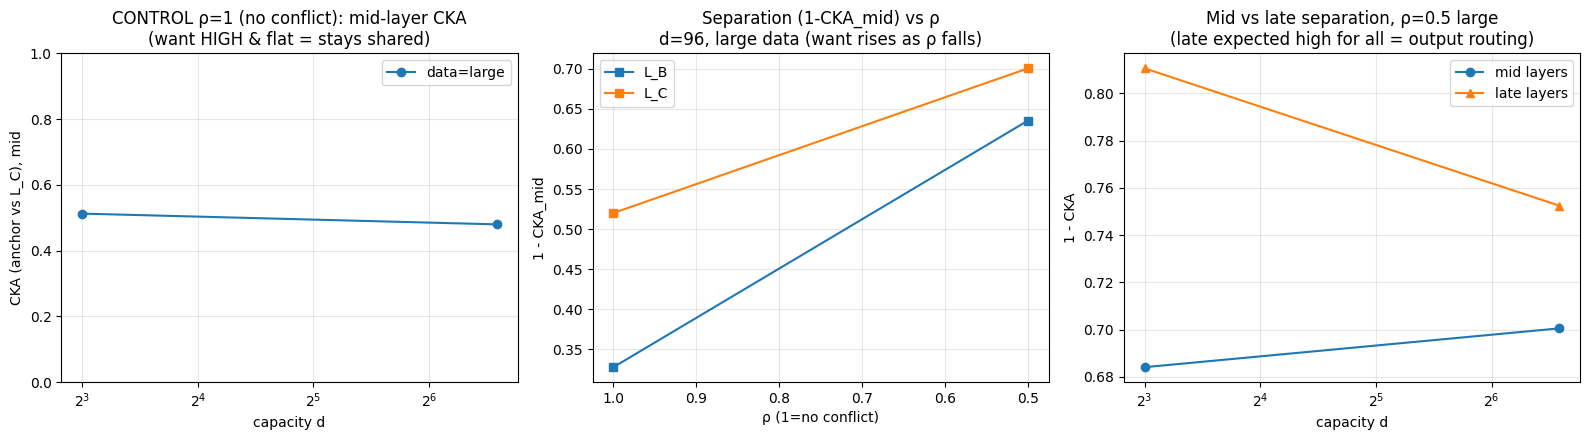

saved exp8_main.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np

R = json.load(open(CKPT))
def agg(filt, key):
    vals = [r[key] for r in R if all(r[k]==v for k,v in filt.items()) and r.get(key) is not None]
    return (np.mean(vals), np.std(vals)) if vals else (None,None)

# ---- Plot 1: rho=1 control, mid-layer CKA vs capacity, by data ----
fig, axes = plt.subplots(1, 3, figsize=(16,4.5))
ax=axes[0]
for data_key in DATA_SWEEP:
    ys=[agg({"rho":1.0,"data":data_key,"d":d,"lang":"L_C"},"cka_mid")[0] for d in D_LIST]
    ax.plot(D_LIST, ys, marker="o", label=f"data={data_key}")
ax.set_title("CONTROL ρ=1 (no conflict): mid-layer CKA\n(want HIGH & flat = stays shared)")
ax.set_xlabel("capacity d"); ax.set_ylabel("CKA (anchor vs L_C), mid"); ax.set_xscale("log",base=2)
ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(0,1)

# ---- Plot 2: separation vs rho, at largest d, large data ----
ax=axes[1]
for lang in NONANCHOR:
    ys=[1-agg({"rho":rho,"data":"large","d":96,"lang":lang},"cka_mid")[0] if agg({"rho":rho,"data":"large","d":96,"lang":lang},"cka_mid")[0] else None for rho in RHO_SWEEP]
    ax.plot(RHO_SWEEP, ys, marker="s", label=lang)
ax.set_title("Separation (1-CKA_mid) vs ρ\nd=96, large data (want rises as ρ falls)")
ax.set_xlabel("ρ (1=no conflict)"); ax.set_ylabel("1 - CKA_mid"); ax.invert_xaxis()
ax.legend(); ax.grid(alpha=0.3)

# ---- Plot 3: mid vs late, at rho=0.5 large data ----
ax=axes[2]
mid=[1-agg({"rho":0.5,"data":"large","d":d,"lang":"L_C"},"cka_mid")[0] if agg({"rho":0.5,"data":"large","d":d,"lang":"L_C"},"cka_mid")[0] else None for d in D_LIST]
late=[1-agg({"rho":0.5,"data":"large","d":d,"lang":"L_C"},"cka_late")[0] if agg({"rho":0.5,"data":"large","d":d,"lang":"L_C"},"cka_late")[0] else None for d in D_LIST]
ax.plot(D_LIST, mid, marker="o", label="mid layers")
ax.plot(D_LIST, late, marker="^", label="late layers")
ax.set_title("Mid vs late separation, ρ=0.5 large\n(late expected high for all = output routing)")
ax.set_xlabel("capacity d"); ax.set_ylabel("1 - CKA"); ax.set_xscale("log",base=2)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("exp8_main.png", dpi=130, bbox_inches="tight"); plt.show()
print("saved exp8_main.png")

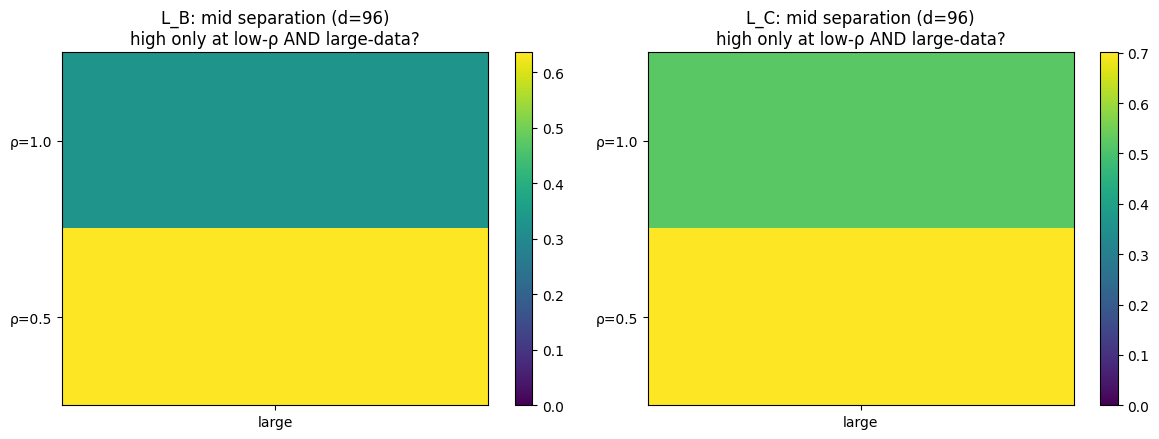

saved exp8_interaction.png

seed   rho   data    d  lang  cka_mid  cka_late   acc     gap
   0   0.5  large    8   L_B    0.400     0.242  0.42    +nan
   0   0.5  large    8   L_C    0.316     0.189  0.42    +nan
   0   0.5  large   96   L_B    0.365     0.221  0.48    +nan
   0   0.5  large   96   L_C    0.299     0.248  0.46    +nan
   0   1.0  large    8   L_B    0.674     0.684  0.58    +nan
   0   1.0  large    8   L_C    0.513     0.382  0.57    +nan
   0   1.0  large   96   L_B    0.672     0.490  0.63    +nan
   0   1.0  large   96   L_C    0.480     0.252  0.61    +nan


In [11]:
# ---- Plot 4: the ρ × data interaction heatmap, at d=96, mid-layer separation ----
fig, axes = plt.subplots(1, len(NONANCHOR), figsize=(12,4.5))
for ax, lang in zip(axes, NONANCHOR):
    M = np.full((len(RHO_SWEEP), len(DATA_SWEEP)), np.nan)
    for i,rho in enumerate(RHO_SWEEP):
        for j,dk in enumerate(DATA_SWEEP):
            v = agg({"rho":rho,"data":dk,"d":96,"lang":lang},"cka_mid")[0]
            if v is not None: M[i,j] = 1-v
    im=ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=np.nanmax(M) if not np.isnan(M).all() else 1)
    ax.set_xticks(range(len(DATA_SWEEP))); ax.set_xticklabels(list(DATA_SWEEP.keys()))
    ax.set_yticks(range(len(RHO_SWEEP))); ax.set_yticklabels([f"ρ={r}" for r in RHO_SWEEP])
    ax.set_title(f"{lang}: mid separation (d=96)\nhigh only at low-ρ AND large-data?")
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig("exp8_interaction.png", dpi=130, bbox_inches="tight"); plt.show()
print("saved exp8_interaction.png")

# ---- dump a flat table for eyeballing ----
print(f"\n{'seed':>4} {'rho':>5} {'data':>6} {'d':>4} {'lang':>5} {'cka_mid':>8} {'cka_late':>9} {'acc':>5} {'gap':>7}")
for r in sorted(R, key=lambda x:(x['seed'],x['rho'],x['data'],x['d'],x['lang'])):
    cm = f"{r['cka_mid']:.3f}" if r.get('cka_mid') else " -- "
    cl = f"{r['cka_late']:.3f}" if r.get('cka_late') else " -- "
    print(f"{r['seed']:>4} {r['rho']:>5} {r['data']:>6} {r['d']:>4} {r['lang']:>5} {cm:>8} {cl:>9} {r['acc_lang']:>5.2f} {r['loss_gap']:>+7.3f}")

## 10. What to tell me after the run

Paste me three things and we decide the next move together — no new plan until we see these:

1. **Plot 1 (ρ=1 control).** Is mid-layer CKA high and flat? (clean theory floor vs Exp6 ghost)
2. **Plot 4 (interaction).** Is mid separation bright only in the low-ρ + large-data corner?
3. **Plot 3 (mid vs late).** Is late always separated while mid is conditional?

If (1) is clean and (2) shows the corner, the ρ×data×capacity story is real and we
move to writing + the Gemma-2 arm. If (1) fails (mid separates even at ρ=1), we stop
and diagnose the measurement before anything else — that is the single most important
thing this run tells us.

In [12]:
# ============================================================
# NOISE-FLOOR DIAGNOSTIC — is mid-layer CKA confounded by word order?
# Four comparisons, all at d=96, ρ=1 (zero conflict), large data, mid layers.
#   (A) L_A vs L_A, SAME model, SAME data        -> upper bound (should be ~1.0)
#   (B) L_A vs L_A, two models, DIFFERENT seeds  -> training-noise floor
#   (C) L_A vs L_B (partial reversal), ρ=1        -> word-order effect, no conflict
#   (D) L_A vs L_C (full reversal),    ρ=1        -> word-order effect, no conflict
# If (C)/(D) >> (B), separation is driven by word order, not computation. CKA is confounded.
# ============================================================
DIAG_D = 96
diag_seed = 0
rules, _ = build_grammar(diag_seed)
cmap = build_conflict_map(rules, diag_seed)
tree_bank = make_tree_bank(rules, ANCHOR_TREES, diag_seed)

# train two anchor-inclusive models on identical data but different init seeds
packed = {ANCHOR: pack_language(tree_bank, ANCHOR, cmap, 1.0, diag_seed, ANCHOR_TREES)}
for lang in NONANCHOR:
    packed[lang] = pack_language(tree_bank, lang, cmap, 1.0, diag_seed, DATA_SWEEP["large"])
mix = {ANCHOR: 0.70, "L_B": 0.15, "L_C": 0.15}

print("training model 1 ..."); m1, _ = train_model(packed, mix, DIAG_D, seed=0)
print("training model 2 (diff init) ..."); m2, _ = train_model(packed, mix, DIAG_D, seed=99)

# eval packs (ρ=1, parallel trees)
ev = {lang: make_eval_pack(tree_bank, lang, cmap, 1.0, diag_seed, n_eval=300) for lang in LANG_NAMES}

H1 = {lang: extract_hidden_states(m1, ev[lang]["idx"]) for lang in LANG_NAMES}
H2A = extract_hidden_states(m2, ev[ANCHOR]["idx"])

def mid_cka(Ha, pa, Hb, pb):
    vals = []
    for L in MID_LAYERS:
        Xa, Xb = collect_matched(Ha, pa, Hb, pb, L)
        if Xa is None: continue
        if Xa.shape[0] > 4000:
            sel = torch.randperm(Xa.shape[0])[:4000]; Xa, Xb = Xa[sel], Xb[sel]
        vals.append(cka(Xa, Xb))
    return sum(vals)/len(vals) if vals else None

A = mid_cka(H1[ANCHOR], ev[ANCHOR], H1[ANCHOR], ev[ANCHOR])          # same model, same lang
B = mid_cka(H1[ANCHOR], ev[ANCHOR], H2A,        ev[ANCHOR])          # diff seed, same lang  = NOISE FLOOR
C = mid_cka(H1[ANCHOR], ev[ANCHOR], H1["L_B"],  ev["L_B"])           # word order (partial), ρ=1
D = mid_cka(H1[ANCHOR], ev[ANCHOR], H1["L_C"],  ev["L_C"])           # word order (full),    ρ=1

print("\n================ NOISE-FLOOR DIAGNOSTIC (mid-layer CKA) ================")
print(f"(A) L_A vs L_A, same model      : {A:.3f}   (sanity, want ~1.0)")
print(f"(B) L_A vs L_A, diff seed       : {B:.3f}   <-- NOISE FLOOR")
print(f"(C) L_A vs L_B, word-order ρ=1  : {C:.3f}   (sep = {1-C:.3f})")
print(f"(D) L_A vs L_C, word-order ρ=1  : {D:.3f}   (sep = {1-D:.3f})")
print("-"*70)
if B is not None and D is not None:
    if (B - D) > 2*(1 - B) and (1 - B) < 0.15:
        print("VERDICT: word order drives separation at ρ=1 while same-lang stays near 1.")
        print("         -> CKA is confounded by position/word-order. Switch to a causal measure.")
    elif (1 - B) > 0.25:
        print("VERDICT: even same-language different-seed separates a lot.")
        print("         -> CKA noise floor is high; metric is unreliable here regardless of word order.")
    else:
        print("VERDICT: word order does NOT fully explain separation; conflict/other may be real. Investigate.")
print("="*70)

training model 1 ...
training model 2 (diff init) ...

================ NOISE-FLOOR DIAGNOSTIC (mid-layer CKA) ================
(A) L_A vs L_A, same model      : 1.000   (sanity, want ~1.0)
(B) L_A vs L_A, diff seed       : 0.723   <-- NOISE FLOOR
(C) L_A vs L_B, word-order ρ=1  : 0.657   (sep = 0.343)
(D) L_A vs L_C, word-order ρ=1  : 0.474   (sep = 0.526)
----------------------------------------------------------------------
VERDICT: even same-language different-seed separates a lot.
         -> CKA noise floor is high; metric is unreliable here regardless of word order.


In [13]:
# ============================================================
# CAUSAL SEPARATION MEASURE — interchange accuracy (replaces CKA)
# Patch anchor's mid-layer activation at a leaf onto the SAME leaf in L_X.
# Shared computation  -> L_X still predicts correctly after patch (high acc).
# Separated computation -> prediction breaks (low acc).
# No init-noise floor: it's a behavioral question inside ONE model.
# ============================================================
if not hasattr(TinyRotaryGPT, "forward_with_patch"):
    def forward_with_patch(self, idx, patch_layer=None, patch_mask=None, patch_values=None):
        x = self.tok_emb(idx)
        for l, blk in enumerate(self.blocks):
            x = blk(x)
            if patch_layer is not None and l == patch_layer:
                x = x.clone()
                x[patch_mask] = patch_values.to(x.dtype)
        x = self.ln_f(x)
        return self.head(x)            # return logits, patched
    TinyRotaryGPT.forward_with_patch = forward_with_patch

@torch.no_grad()
def layer_activations_at(model, idx_tensor, layer, batch_size=32, device=DEVICE):
    """Residual stream right AFTER block `layer`, shape (N, T, d). CPU float."""
    model.eval()
    acts = []
    def hook(m, i, o): acts.append(o.detach().float().cpu())
    h = model.blocks[layer].register_forward_hook(hook)
    try:
        for i in range(0, idx_tensor.shape[0], batch_size):
            with autocast_ctx(): _ = model(idx_tensor[i:i+batch_size].to(device))
    finally:
        h.remove()
    return torch.cat(acts, 0)

@torch.no_grad()
def interchange_accuracy(model, pack_src, pack_tgt, layer, device=DEVICE, batch_size=32, max_pairs=4000):
    """For matched leaves between src (anchor donor) and tgt (receiver language):
       baseline = tgt predicts its own next token at the leaf, unpatched
       patched  = same, but tgt's activation at that leaf replaced by src's at the
                  SAME canonical leaf
       returns (baseline_acc, patched_acc, n). High patched_acc => shared computation."""
    pos_s = _positions_for_leaves(pack_src).to(device)
    pos_t = _positions_for_leaves(pack_tgt).to(device)
    n_tr = min(pos_s.shape[0], pos_t.shape[0])
    max_lid = min(pos_s.shape[1], pos_t.shape[1])
    pos_s, pos_t = pos_s[:n_tr,:max_lid], pos_t[:n_tr,:max_lid]
    valid = (pos_s >= 0) & (pos_t >= 0)

    idx_s = pack_src["idx"][:n_tr].to(device)
    idx_t = pack_tgt["idx"][:n_tr].to(device)

    A_src = layer_activations_at(model, idx_s, layer, batch_size, device).to(device)  # (n_tr,T,d)

    base_correct = patch_correct = total = 0
    for i in range(0, n_tr, batch_size):
        j = min(i+batch_size, n_tr)
        bt = idx_t[i:j]
        bA = A_src[i:j]
        b = bt.shape[0]
        vt = valid[i:j]
        logits_base = model(bt)[0]
        mask = torch.zeros(b, bt.shape[1], dtype=torch.bool, device=device)
        pv_vals, tgt_pos_list, tgt_tok_list = [], [], []
        for r in range(b):
            lids = vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            ps = pos_s[i+r, lids]
            pt = pos_t[i+r, lids]
            ok = (pt+1) < bt.shape[1]
            ps, pt = ps[ok], pt[ok]
            if pt.numel()==0: continue
            mask[r, pt] = True
            pv_vals.append(bA[r, ps])
            tgt_pos_list.append(torch.stack([torch.full_like(pt, r), pt], 1))
            tgt_tok_list.append(bt[r, pt+1])
        if not pv_vals: continue
        patch_values = torch.cat(pv_vals, 0)
        logits_patch = model.forward_with_patch(bt, patch_layer=layer,
                                                patch_mask=mask, patch_values=patch_values)
        poss = torch.cat(tgt_pos_list, 0); toks = torch.cat(tgt_tok_list, 0)
        pb = logits_base[poss[:,0], poss[:,1]].argmax(-1)
        pp = logits_patch[poss[:,0], poss[:,1]].argmax(-1)
        base_correct  += (pb == toks).sum().item()
        patch_correct += (pp == toks).sum().item()
        total += toks.numel()
        if total >= max_pairs: break
    if total == 0: return None, None, 0
    return base_correct/total, patch_correct/total, total

print("causal interchange measure ready")

causal interchange measure ready


In [14]:
# ============================================================
# CAUSAL DIAGNOSTIC — same 4 comparisons as the CKA noise-floor test,
# now via interchange accuracy. Expect the init-noise floor to VANISH.
# Retention = patched_acc / baseline_acc. ~1.0 = shared computation; low = separated.
# Uses m1 and ρ=1 eval packs `ev` from the previous diagnostic cell.
# ============================================================
PATCH_LAYER = MID_LAYERS[len(MID_LAYERS)//2]
print(f"patching at layer {PATCH_LAYER}\n")

def retention(donor_pack, recv_pack, tag):
    base, patch, n = interchange_accuracy(m1, donor_pack, recv_pack, PATCH_LAYER)
    if base is None:
        print(f"{tag}: no matched pairs"); return
    ret = patch/base if base>0 else float('nan')
    print(f"{tag:32s} baseline={base:.3f}  patched={patch:.3f}  retention={ret:.3f}  (n={n})")
    return ret

print("================ CAUSAL INTERCHANGE DIAGNOSTIC ================")
rA = retention(ev[ANCHOR], ev[ANCHOR], "(A) anchor->anchor (same model)")
rC = retention(ev[ANCHOR], ev["L_B"],  "(C) anchor->L_B  word-order rho=1")
rD = retention(ev[ANCHOR], ev["L_C"],  "(D) anchor->L_C  word-order rho=1")
print("-"*62)

patching at layer 4

================ CAUSAL INTERCHANGE DIAGNOSTIC ================
(A) anchor->anchor (same model)  baseline=0.634  patched=0.634  retention=1.000  (n=7483)
(C) anchor->L_B  word-order rho=1 baseline=0.650  patched=0.412  retention=0.634  (n=7483)
(D) anchor->L_C  word-order rho=1 baseline=0.646  patched=0.399  retention=0.617  (n=7483)
--------------------------------------------------------------


In [15]:
# ============================================================
# POSITION-MATCHED interchange: only patch leaves where donor and receiver
# sit at the SAME sequence position, so rotary phase matches at the paste site.
# If retention -> ~1.0 here but was ~0.6 unmatched, then the ~0.6 was POSITION,
# not computational separation: word order explains it, rho=1 is genuinely shared.
# ============================================================
@torch.no_grad()
def interchange_accuracy_posmatched(model, pack_src, pack_tgt, layer,
                                    device=DEVICE, batch_size=32, max_pairs=4000,
                                    require_same_pos=True):
    pos_s = _positions_for_leaves(pack_src).to(device)
    pos_t = _positions_for_leaves(pack_tgt).to(device)
    n_tr = min(pos_s.shape[0], pos_t.shape[0]); max_lid = min(pos_s.shape[1], pos_t.shape[1])
    pos_s, pos_t = pos_s[:n_tr,:max_lid], pos_t[:n_tr,:max_lid]
    valid = (pos_s >= 0) & (pos_t >= 0)
    if require_same_pos:
        valid = valid & (pos_s == pos_t)          # <-- the only change
    idx_s = pack_src["idx"][:n_tr].to(device); idx_t = pack_tgt["idx"][:n_tr].to(device)
    A_src = layer_activations_at(model, idx_s, layer, batch_size, device).to(device)
    base_correct = patch_correct = total = 0
    for i in range(0, n_tr, batch_size):
        j = min(i+batch_size, n_tr); bt = idx_t[i:j]; bA = A_src[i:j]; b = bt.shape[0]; vt = valid[i:j]
        logits_base = model(bt)[0]
        mask = torch.zeros(b, bt.shape[1], dtype=torch.bool, device=device)
        pv_vals, tgt_pos_list, tgt_tok_list = [], [], []
        for r in range(b):
            lids = vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            ps = pos_s[i+r, lids]; pt = pos_t[i+r, lids]
            ok = (pt+1) < bt.shape[1]; ps, pt = ps[ok], pt[ok]
            if pt.numel()==0: continue
            mask[r, pt] = True; pv_vals.append(bA[r, ps])
            tgt_pos_list.append(torch.stack([torch.full_like(pt, r), pt], 1))
            tgt_tok_list.append(bt[r, pt+1])
        if not pv_vals: continue
        logits_patch = model.forward_with_patch(bt, patch_layer=layer, patch_mask=mask,
                                                patch_values=torch.cat(pv_vals,0))
        poss = torch.cat(tgt_pos_list,0); toks = torch.cat(tgt_tok_list,0)
        base_correct  += (logits_base[poss[:,0],poss[:,1]].argmax(-1)==toks).sum().item()
        patch_correct += (logits_patch[poss[:,0],poss[:,1]].argmax(-1)==toks).sum().item()
        total += toks.numel()
        if total >= max_pairs: break
    if total==0: return None, None, 0
    return base_correct/total, patch_correct/total, total

print("================ POSITION-MATCHED CAUSAL DIAGNOSTIC ================")
for tag, recv in [("(A) anchor->anchor", ANCHOR), ("(C) anchor->L_B", "L_B"), ("(D) anchor->L_C", "L_C")]:
    base, patch, n = interchange_accuracy_posmatched(m1, ev[ANCHOR], ev[recv], PATCH_LAYER)
    if base is None: print(f"{tag:22s} no same-position leaves (n=0)"); continue
    print(f"{tag:22s} baseline={base:.3f} patched={patch:.3f} retention={patch/base:.3f} (n={n})")
print("-"*64)

================ POSITION-MATCHED CAUSAL DIAGNOSTIC ================
(A) anchor->anchor     baseline=0.634 patched=0.634 retention=1.000 (n=7483)
(C) anchor->L_B        baseline=0.659 patched=0.638 retention=0.969 (n=2539)
(D) anchor->L_C        baseline=0.605 patched=0.428 retention=0.707 (n=152)
----------------------------------------------------------------


In [16]:
# ============================================================
# POSITION-MATCHED interchange: only patch leaves where donor and receiver
# sit at the SAME sequence position, so rotary phase matches at the paste site.
# If retention -> ~1.0 here but was ~0.6 unmatched, then the ~0.6 was POSITION,
# not computational separation: word order explains it, rho=1 is genuinely shared.
# ============================================================
@torch.no_grad()
def interchange_accuracy_posmatched(model, pack_src, pack_tgt, layer,
                                    device=DEVICE, batch_size=32, max_pairs=4000,
                                    require_same_pos=True):
    pos_s = _positions_for_leaves(pack_src).to(device)
    pos_t = _positions_for_leaves(pack_tgt).to(device)
    n_tr = min(pos_s.shape[0], pos_t.shape[0]); max_lid = min(pos_s.shape[1], pos_t.shape[1])
    pos_s, pos_t = pos_s[:n_tr,:max_lid], pos_t[:n_tr,:max_lid]
    valid = (pos_s >= 0) & (pos_t >= 0)
    if require_same_pos:
        valid = valid & (pos_s == pos_t)          # <-- the only change
    idx_s = pack_src["idx"][:n_tr].to(device); idx_t = pack_tgt["idx"][:n_tr].to(device)
    A_src = layer_activations_at(model, idx_s, layer, batch_size, device).to(device)
    base_correct = patch_correct = total = 0
    for i in range(0, n_tr, batch_size):
        j = min(i+batch_size, n_tr); bt = idx_t[i:j]; bA = A_src[i:j]; b = bt.shape[0]; vt = valid[i:j]
        logits_base = model(bt)[0]
        mask = torch.zeros(b, bt.shape[1], dtype=torch.bool, device=device)
        pv_vals, tgt_pos_list, tgt_tok_list = [], [], []
        for r in range(b):
            lids = vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            ps = pos_s[i+r, lids]; pt = pos_t[i+r, lids]
            ok = (pt+1) < bt.shape[1]; ps, pt = ps[ok], pt[ok]
            if pt.numel()==0: continue
            mask[r, pt] = True; pv_vals.append(bA[r, ps])
            tgt_pos_list.append(torch.stack([torch.full_like(pt, r), pt], 1))
            tgt_tok_list.append(bt[r, pt+1])
        if not pv_vals: continue
        logits_patch = model.forward_with_patch(bt, patch_layer=layer, patch_mask=mask,
                                                patch_values=torch.cat(pv_vals,0))
        poss = torch.cat(tgt_pos_list,0); toks = torch.cat(tgt_tok_list,0)
        base_correct  += (logits_base[poss[:,0],poss[:,1]].argmax(-1)==toks).sum().item()
        patch_correct += (logits_patch[poss[:,0],poss[:,1]].argmax(-1)==toks).sum().item()
        total += toks.numel()
        if total >= max_pairs: break
    if total==0: return None, None, 0
    return base_correct/total, patch_correct/total, total

In [17]:
# ============================================================
# THE REAL ε TEST — does CONFLICT (ρ<1) break computational sharing?
# Position-matched interchange, anchor -> L_B (the high-n trustworthy language).
# Sweep ρ. Split retention by CONFLICTED vs NON-CONFLICTED leaves.
# ============================================================
RHO_TEST = [1.0, 0.7, 0.5]
DIAG_D   = 96
diag_seed = 0

def conflicted_leafids(pack_anchor, pack_lang):
    pa = _positions_for_leaves(pack_anchor); pl = _positions_for_leaves(pack_lang)
    n = min(pa.shape[0], pl.shape[0]); m = min(pa.shape[1], pl.shape[1])
    pa, pl = pa[:n,:m], pl[:n,:m]
    ia, il = pack_anchor["idx"][:n], pack_lang["idx"][:n]
    conf = torch.zeros(n, m, dtype=torch.bool)
    for t in range(n):
        for lid in range(m):
            if pa[t,lid]>=0 and pl[t,lid]>=0:
                conf[t,lid] = (ia[t,pa[t,lid]].item() != il[t,pl[t,lid]].item())
    return conf

@torch.no_grad()
def interchange_split(model, pack_src, pack_tgt, layer, conf_mask, device=DEVICE, batch_size=32):
    pos_s = _positions_for_leaves(pack_src).to(device); pos_t = _positions_for_leaves(pack_tgt).to(device)
    n_tr = min(pos_s.shape[0], pos_t.shape[0]); max_lid = min(pos_s.shape[1], pos_t.shape[1])
    pos_s, pos_t = pos_s[:n_tr,:max_lid], pos_t[:n_tr,:max_lid]
    conf = conf_mask[:n_tr,:max_lid].to(device)
    valid = (pos_s>=0)&(pos_t>=0)&(pos_s==pos_t)
    idx_s = pack_src["idx"][:n_tr].to(device); idx_t = pack_tgt["idx"][:n_tr].to(device)
    A_src = layer_activations_at(model, idx_s, layer, batch_size, device).to(device)
    acc = {True:[0,0,0], False:[0,0,0]}
    for i in range(0, n_tr, batch_size):
        j=min(i+batch_size,n_tr); bt=idx_t[i:j]; bA=A_src[i:j]; b=bt.shape[0]; vt=valid[i:j]; cf=conf[i:j]
        logits_base = model(bt)[0]
        mask=torch.zeros(b,bt.shape[1],dtype=torch.bool,device=device); rows=[]; pv=[]
        for r in range(b):
            lids=vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            ps=pos_s[i+r,lids]; pt=pos_t[i+r,lids]
            ok=(pt+1)<bt.shape[1]; ps,pt,lids=ps[ok],pt[ok],lids[ok]
            if pt.numel()==0: continue
            mask[r,pt]=True; pv.append(bA[r,ps])
            for k in range(pt.numel()):
                rows.append((r,int(pt[k]),int(bt[r,pt[k]+1]),bool(cf[r,lids[k]])))
        if not pv: continue
        lp = model.forward_with_patch(bt,patch_layer=layer,patch_mask=mask,patch_values=torch.cat(pv,0))
        for (r,p,tok,isc) in rows:
            acc[isc][0]+=int(logits_base[r,p].argmax(-1).item()==tok)
            acc[isc][1]+=int(lp[r,p].argmax(-1).item()==tok)
            acc[isc][2]+=1
    def ret(a): return (a[0]/a[2] if a[2] else float('nan'), a[1]/a[2] if a[2] else float('nan'), a[2])
    return ret(acc[True]), ret(acc[False])

print("================ ε TEST: retention vs ρ, split by leaf type ================")
print(f"{'rho':>5} | {'CONFLICTED base/patch/ret (n)':>36} | {'NON-CONFLICTED base/patch/ret (n)':>38}")
print("-"*90)
mix = {ANCHOR:0.70,"L_B":0.15,"L_C":0.15}
for rho in RHO_TEST:
    packed={ANCHOR:pack_language(tree_bank,ANCHOR,cmap,1.0,diag_seed,ANCHOR_TREES)}
    for lang in NONANCHOR:
        packed[lang]=pack_language(tree_bank,lang,cmap,rho,diag_seed,DATA_SWEEP["large"])
    model,_=train_model(packed,mix,DIAG_D,seed=0)
    evr={lang:make_eval_pack(tree_bank,lang,cmap,rho,diag_seed,n_eval=400) for lang in [ANCHOR,"L_B"]}
    conf=conflicted_leafids(evr[ANCHOR],evr["L_B"])
    (cb,cp,cn),(nb_,np_,nn_)=interchange_split(model,evr[ANCHOR],evr["L_B"],PATCH_LAYER,conf)
    cret = cp/cb if cb and cb>0 else float('nan')
    nret = np_/nb_ if nb_ and nb_>0 else float('nan')
    print(f"{rho:>5} | {cb:>6.3f}/{cp:>5.3f}/{cret:>5.3f} (n={cn:>5}) | {nb_:>6.3f}/{np_:>5.3f}/{nret:>5.3f} (n={nn_:>5})")
print("-"*90)

================ ε TEST: retention vs ρ, split by leaf type ================
  rho |        CONFLICTED base/patch/ret (n) |      NON-CONFLICTED base/patch/ret (n)
------------------------------------------------------------------------------------------
  1.0 |    nan/  nan/  nan (n=    0) |  0.681/0.656/0.963 (n= 3471)
  0.7 |  0.355/0.570/1.605 (n=  535) |  0.555/0.555/1.000 (n= 2936)
  0.5 |  0.361/0.482/1.335 (n=  868) |  0.506/0.504/0.997 (n= 2603)
------------------------------------------------------------------------------------------


In [19]:
# ============================================================
# OPTION B — clean ε isolation. L_B differs from anchor by LOOKUP CONFLICT ONLY,
# same word order (no reversal). Every leaf is position-matched for free.
# Conflict applied DETERMINISTICALLY: a fixed (1-ρ) fraction of eligible leaves
# conflict every time, chosen by hashing the leaf-id (stable across train/eval).
# ============================================================
RHO_TEST = [1.0, 0.7, 0.5, 0.3]
DIAG_D   = 96
diag_seed = 0

def linearize_optB_with_ids(node, cmap_lang, rho):
    idmap={}; c=[0]
    def idwalk(n,path):
        if isinstance(n,int): idmap[tuple(path)]=c[0]; c[0]+=1; return
        (_lv,_ix),ch=n
        for k,ck in enumerate(ch): idwalk(ck,path+[k])
    idwalk(node,[])
    toks=[]; ids=[]; conf=[]
    def emit(n,path,parent):
        if isinstance(n,int):
            lid=idmap[tuple(path)]; term=n; is_conf=False
            if parent in cmap_lang and term in cmap_lang[parent]:
                frac=((lid*2654435761)%1000)/1000.0
                if frac >= rho:
                    term=cmap_lang[parent][term]; is_conf=True
            toks.append(term); ids.append(lid); conf.append(is_conf); return
        (level,ix),ch=n
        for k,child in enumerate(ch):
            emit(child,path+[k],(level,ix))
    emit(node,[],None)
    return toks,ids,conf

def pack_optB(tree_bank, lang_name, cmap, rho, n_trees):
    cmap_lang = cmap[lang_name] if lang_name in cmap else {}
    stream=[]
    for tree in tree_bank[:n_trees]:
        stream.append(BOS[lang_name])
        toks,_,_=linearize_optB_with_ids(tree, cmap_lang, rho)
        stream.extend(toks)
    stream=torch.tensor(stream,dtype=torch.long)
    nc=len(stream)//(SEQ_LEN+1)
    return stream[:nc*(SEQ_LEN+1)].view(nc,SEQ_LEN+1)

def evalpack_optB(tree_bank, lang_name, cmap, rho, n_eval=400):
    cmap_lang = cmap[lang_name] if lang_name in cmap else {}
    rows=[]; leaf_rows=[]; conf_rows=[]
    for tree in tree_bank[:n_eval]:
        toks,ids,conf=linearize_optB_with_ids(tree, cmap_lang, rho)
        rows.append([BOS[lang_name]]+toks); leaf_rows.append([-1]+ids); conf_rows.append([False]+conf)
    maxlen=max(len(r) for r in rows)
    assert maxlen<=SEQ_LEN+1, f"tree {maxlen} > ctx {SEQ_LEN+1}"
    idx=torch.zeros(len(rows),maxlen,dtype=torch.long)
    leaf=torch.full((len(rows),maxlen),-1,dtype=torch.long)
    cfl=torch.zeros(len(rows),maxlen,dtype=torch.bool)
    for t,(r,l,cf) in enumerate(zip(rows,leaf_rows,conf_rows)):
        idx[t,:len(r)]=torch.tensor(r); leaf[t,:len(l)]=torch.tensor(l); cfl[t,:len(cf)]=torch.tensor(cf)
    return {"idx":idx,"leaf_id":leaf,"conf":cfl}

@torch.no_grad()
def interchange_split_optB(model, pack_src, pack_tgt, layer, device=DEVICE, batch_size=32):
    pos_s=_positions_for_leaves(pack_src).to(device); pos_t=_positions_for_leaves(pack_tgt).to(device)
    n_tr=min(pos_s.shape[0],pos_t.shape[0]); m=min(pos_s.shape[1],pos_t.shape[1])
    pos_s,pos_t=pos_s[:n_tr,:m],pos_t[:n_tr,:m]
    valid=(pos_s>=0)&(pos_t>=0)&(pos_s==pos_t)
    idx_s=pack_src["idx"][:n_tr].to(device); idx_t=pack_tgt["idx"][:n_tr].to(device)
    A_src=layer_activations_at(model,idx_s,layer,batch_size,device).to(device)
    acc={True:[0,0,0],False:[0,0,0]}
    for i in range(0,n_tr,batch_size):
        j=min(i+batch_size,n_tr); bt=idx_t[i:j]; bA=A_src[i:j]; b=bt.shape[0]; vt=valid[i:j]
        logits_base=model(bt)[0]
        mask=torch.zeros(b,bt.shape[1],dtype=torch.bool,device=device); rows=[]; pv=[]
        for r in range(b):
            lids=vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            ps=pos_s[i+r,lids]; pt=pos_t[i+r,lids]
            ok=(pt+1)<bt.shape[1]; ps,pt,lids=ps[ok],pt[ok],lids[ok]
            if pt.numel()==0: continue
            mask[r,pt]=True; pv.append(bA[r,ps])
            for k in range(pt.numel()):
                isc=bool(pack_tgt["conf"][i+r, int(pt[k])].item())
                rows.append((r,int(pt[k]),int(bt[r,pt[k]+1]),isc))
        if not pv: continue
        lp=model.forward_with_patch(bt,patch_layer=layer,patch_mask=mask,patch_values=torch.cat(pv,0))
        for (r,p,tok,isc) in rows:
            acc[isc][0]+=int(logits_base[r,p].argmax(-1).item()==tok)
            acc[isc][1]+=int(lp[r,p].argmax(-1).item()==tok)
            acc[isc][2]+=1
    def ret(a): return (a[0]/a[2] if a[2] else float('nan'), a[1]/a[2] if a[2] else float('nan'), a[2])
    return ret(acc[True]), ret(acc[False])

print("============ OPTION B: epsilon TEST (conflict-only L_B, no word order) ============")
print(f"{'rho':>5} | {'CONFLICTED base/patch/ret (n)':>34} | {'NON-CONF base/patch/ret (n)':>34}")
print("-"*82)
mix={ANCHOR:0.70,"L_B":0.30}
for rho in RHO_TEST:
    packed={ANCHOR:pack_optB(tree_bank,ANCHOR,cmap,1.0,ANCHOR_TREES),
            "L_B":pack_optB(tree_bank,"L_B",cmap,rho,DATA_SWEEP["large"])}
    model,_=train_model(packed,mix,DIAG_D,seed=0)
    eva=evalpack_optB(tree_bank,ANCHOR,cmap,1.0,n_eval=400)
    evb=evalpack_optB(tree_bank,"L_B",cmap,rho,n_eval=400)
    (cb,cp,cn),(nb_,np_,nn_)=interchange_split_optB(model,eva,evb,PATCH_LAYER)
    cret=cp/cb if cb and cb>0 else float('nan'); nret=np_/nb_ if nb_ and nb_>0 else float('nan')
    print(f"{rho:>5} | {cb:>6.3f}/{cp:>5.3f}/{cret:>5.3f} (n={cn:>5}) | {nb_:>6.3f}/{np_:>5.3f}/{nret:>5.3f} (n={nn_:>5})")
print("-"*82)

============ OPTION B: epsilon TEST (conflict-only L_B, no word order) ============
  rho |      CONFLICTED base/patch/ret (n) |        NON-CONF base/patch/ret (n)
----------------------------------------------------------------------------------
  1.0 |    nan/  nan/  nan (n=    0) |  0.645/0.645/1.000 (n=98118)
  0.7 |  0.710/0.637/0.897 (n=12853) |  0.614/0.562/0.916 (n=85265)
  0.5 |  0.694/0.461/0.664 (n=21755) |  0.590/0.538/0.912 (n=76363)
  0.3 |  0.694/0.391/0.564 (n=30221) |  0.560/0.505/0.901 (n=67897)
----------------------------------------------------------------------------------


In [20]:
# ============================================================
# CHECK 1 — token-identity artifact control.
# Patch anchor activation at position (leaf_pos - 1); predict the leaf's OWN token
# at leaf_pos. The predicted thing is the conflicted token itself, produced from
# context BEFORE the swap enters the input -> no downstream-of-known-difference
# contamination. If conflicted retention STILL falls with rho, the eps result is real.
# ============================================================
@torch.no_grad()
def interchange_tokenbefore(model, pack_src, pack_tgt, layer, device=DEVICE, batch_size=32):
    pos_s=_positions_for_leaves(pack_src).to(device); pos_t=_positions_for_leaves(pack_tgt).to(device)
    n_tr=min(pos_s.shape[0],pos_t.shape[0]); m=min(pos_s.shape[1],pos_t.shape[1])
    pos_s,pos_t=pos_s[:n_tr,:m],pos_t[:n_tr,:m]
    valid=(pos_s>=0)&(pos_t>=0)&(pos_s==pos_t)
    idx_s=pack_src["idx"][:n_tr].to(device); idx_t=pack_tgt["idx"][:n_tr].to(device)
    A_src=layer_activations_at(model,idx_s,layer,batch_size,device).to(device)
    acc={True:[0,0,0],False:[0,0,0]}
    for i in range(0,n_tr,batch_size):
        j=min(i+batch_size,n_tr); bt=idx_t[i:j]; bA=A_src[i:j]; b=bt.shape[0]; vt=valid[i:j]
        logits_base=model(bt)[0]
        mask=torch.zeros(b,bt.shape[1],dtype=torch.bool,device=device); rows=[]; pv=[]
        for r in range(b):
            lids=vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            pt=pos_t[i+r,lids]
            ok=(pt>=1); pt,lids=pt[ok],lids[ok]
            if pt.numel()==0: continue
            patch_pos=pt-1
            mask[r,patch_pos]=True
            pv.append(bA[r,patch_pos])
            for k in range(pt.numel()):
                isc=bool(pack_tgt["conf"][i+r,int(pt[k])].item())
                rows.append((r,int(pt[k]-1),int(bt[r,pt[k]]),isc))
        if not pv: continue
        lp=model.forward_with_patch(bt,patch_layer=layer,patch_mask=mask,patch_values=torch.cat(pv,0))
        for (r,ppred,tok,isc) in rows:
            acc[isc][0]+=int(logits_base[r,ppred].argmax(-1).item()==tok)
            acc[isc][1]+=int(lp[r,ppred].argmax(-1).item()==tok)
            acc[isc][2]+=1
    def ret(a): return (a[0]/a[2] if a[2] else float('nan'), a[1]/a[2] if a[2] else float('nan'), a[2])
    return ret(acc[True]), ret(acc[False])

print("====== CHECK 1: token-BEFORE target (artifact control) ======")
print(f"{'rho':>5} | {'CONFLICTED base/patch/ret (n)':>34} | {'NON-CONF base/patch/ret (n)':>34}")
print("-"*82)
mix={ANCHOR:0.70,"L_B":0.30}
for rho in [1.0,0.7,0.5,0.3]:
    packed={ANCHOR:pack_optB(tree_bank,ANCHOR,cmap,1.0,ANCHOR_TREES),
            "L_B":pack_optB(tree_bank,"L_B",cmap,rho,DATA_SWEEP["large"])}
    model,_=train_model(packed,mix,DIAG_D,seed=0)
    eva=evalpack_optB(tree_bank,ANCHOR,cmap,1.0,n_eval=400)
    evb=evalpack_optB(tree_bank,"L_B",cmap,rho,n_eval=400)
    (cb,cp,cn),(nb_,np_,nn_)=interchange_tokenbefore(model,eva,evb,PATCH_LAYER)
    cret=cp/cb if cb and cb>0 else float('nan'); nret=np_/nb_ if nb_ and nb_>0 else float('nan')
    print(f"{rho:>5} | {cb:>6.3f}/{cp:>5.3f}/{cret:>5.3f} (n={cn:>5}) | {nb_:>6.3f}/{np_:>5.3f}/{nret:>5.3f} (n={nn_:>5})")
print("-"*82)

====== CHECK 1: token-BEFORE target (artifact control) ======
  rho |      CONFLICTED base/patch/ret (n) |        NON-CONF base/patch/ret (n)
----------------------------------------------------------------------------------
  1.0 |    nan/  nan/  nan (n=    0) |  0.644/0.644/1.000 (n=98119)
  0.7 |  0.630/0.137/0.218 (n=12853) |  0.626/0.635/1.016 (n=85266)
  0.5 |  0.641/0.130/0.202 (n=21755) |  0.606/0.625/1.032 (n=76364)
  0.3 |  0.617/0.130/0.211 (n=30221) |  0.591/0.617/1.044 (n=67898)
----------------------------------------------------------------------------------


In [21]:
# ============================================================
# DIRECTION-OF-ERROR — the smoking gun for ε.
# At conflicted leaves, when the pre-leaf anchor patch breaks L_B's prediction,
# WHERE does the mass go? If it flips to the ANCHOR's token, that proves the anchor
# representation causally carries the anchor's value, and installing it makes L_B
# produce the anchor's answer instead of its own. That IS eps, mechanistically.
# ============================================================
def anchor_token_map(tree_bank, cmap_lang, n_eval):
    maps=[]
    for tree in tree_bank[:n_eval]:
        toks,ids,_=linearize_optB_with_ids(tree, {}, 1.0)   # empty cmap => anchor tokens
        maps.append(dict(zip(ids,toks)))
    return maps

@torch.no_grad()
def direction_of_error(model, pack_src, pack_tgt, anchor_tok_maps, layer, device=DEVICE, batch_size=32):
    pos_s=_positions_for_leaves(pack_src).to(device); pos_t=_positions_for_leaves(pack_tgt).to(device)
    n_tr=min(pos_s.shape[0],pos_t.shape[0]); m=min(pos_s.shape[1],pos_t.shape[1])
    pos_s,pos_t=pos_s[:n_tr,:m],pos_t[:n_tr,:m]
    valid=(pos_s>=0)&(pos_t>=0)&(pos_s==pos_t)
    idx_s=pack_src["idx"][:n_tr].to(device); idx_t=pack_tgt["idx"][:n_tr].to(device)
    leaf_t=pack_tgt["leaf_id"][:n_tr]
    A_src=layer_activations_at(model,idx_s,layer,batch_size,device).to(device)
    flip_anchor=keep_B=other=tot=0
    for i in range(0,n_tr,batch_size):
        j=min(i+batch_size,n_tr); bt=idx_t[i:j]; bA=A_src[i:j]; b=bt.shape[0]; vt=valid[i:j]
        mask=torch.zeros(b,bt.shape[1],dtype=torch.bool,device=device); pv=[]; rows=[]
        for r in range(b):
            lids=vt[r].nonzero(as_tuple=True)[0]
            if lids.numel()==0: continue
            pt=pos_t[i+r,lids]; ok=(pt>=1); pt,lids=pt[ok],lids[ok]
            if pt.numel()==0: continue
            mask[r,pt-1]=True; pv.append(bA[r,pt-1])
            for k in range(pt.numel()):
                p=int(pt[k])
                if not bool(pack_tgt["conf"][i+r,p].item()): continue
                lid=int(leaf_t[i+r,p].item())
                tok_B=int(bt[r,p]); tok_anchor=anchor_tok_maps[i+r].get(lid,None)
                if tok_anchor is None: continue
                rows.append((r,p-1,tok_B,tok_anchor))
        if not pv: continue
        lp=model.forward_with_patch(bt,patch_layer=layer,patch_mask=mask,patch_values=torch.cat(pv,0))
        for (r,ppred,tok_B,tok_anchor) in rows:
            pred=int(lp[r,ppred].argmax(-1).item()); tot+=1
            if pred==tok_anchor and tok_anchor!=tok_B: flip_anchor+=1
            elif pred==tok_B: keep_B+=1
            else: other+=1
    if tot==0: return None
    return flip_anchor/tot, keep_B/tot, other/tot, tot

print("====== DIRECTION-OF-ERROR at conflicted leaves (pre-leaf anchor patch) ======")
print(f"{'rho':>5} | {'flip->anchor':>12} | {'kept->B':>8} | {'other':>6} | {'n':>6}")
print("-"*54)
mix={ANCHOR:0.70,"L_B":0.30}
for rho in [0.7,0.5,0.3]:
    packed={ANCHOR:pack_optB(tree_bank,ANCHOR,cmap,1.0,ANCHOR_TREES),
            "L_B":pack_optB(tree_bank,"L_B",cmap,rho,DATA_SWEEP["large"])}
    model,_=train_model(packed,mix,DIAG_D,seed=0)
    eva=evalpack_optB(tree_bank,ANCHOR,cmap,1.0,n_eval=400)
    evb=evalpack_optB(tree_bank,"L_B",cmap,rho,n_eval=400)
    atm=anchor_token_map(tree_bank, cmap["L_B"], n_eval=400)
    res=direction_of_error(model,eva,evb,atm,PATCH_LAYER)
    if res is None: print(f"{rho:>5} | no conflicted leaves"); continue
    fa,kb,ot,n=res
    print(f"{rho:>5} | {fa:>12.3f} | {kb:>8.3f} | {ot:>6.3f} | {n:>6}")
print("-"*54)

====== DIRECTION-OF-ERROR at conflicted leaves (pre-leaf anchor patch) ======
  rho | flip->anchor |  kept->B |  other |      n
------------------------------------------------------
  0.7 |        0.685 |    0.136 |  0.178 |  12853
  0.5 |        0.688 |    0.134 |  0.177 |  21755
  0.3 |        0.694 |    0.128 |  0.178 |  30221
------------------------------------------------------


In [22]:
# ============================================================
# CHANG ET AL. (2022) STYLE SUBSPACE GEOMETRY — the mech-interp measure.
# Separates (a) language MEAN (where the cloud sits -> vocabulary/surface stuff)
# from (b) mean-centered SUBSPACE SHAPE (how variation spreads -> the computation).
# Robust to pointwise init noise because it's a DISTRIBUTIONAL measure, not pairwise.
# ============================================================
import math

def _collect_leaf_activations(model, pack, layer, device=DEVICE):
    H = layer_activations_at(model, pack["idx"], layer, batch_size=32, device=device)
    leaf = pack["leaf_id"]
    mask = leaf >= 0
    return H[mask]

def compute_subspace(acts, var_frac=0.9):
    N, d = acts.shape
    assert N >= d, f"need N>=d, got N={N}, d={d}"
    mu = acts.mean(0)
    ac = acts - mu
    U, S, Vt = torch.linalg.svd(ac.float(), full_matrices=False)
    V = Vt.T
    variances = (S**2) / (N - 1)
    cum = torch.cumsum(variances, 0) / variances.sum().clamp_min(1e-10)
    k = int((cum >= var_frac).nonzero(as_tuple=True)[0][0].item()) + 1
    return mu, V, variances, k

def mean_centered_cov(V, variances, reg_frac=1e-3):
    d = V.shape[0]
    K = V @ torch.diag(variances) @ V.T
    K = K + reg_frac * variances.sum() / d * torch.eye(d)
    return 0.5 * (K + K.T)

def subspace_distance_logeig(K_A, K_B):
    L = torch.linalg.cholesky(K_A)
    Linv = torch.linalg.solve_triangular(L, torch.eye(K_A.shape[0]), upper=False)
    M = Linv @ K_B @ Linv.T
    M = 0.5 * (M + M.T)
    eigs = torch.linalg.eigvalsh(M).clamp_min(1e-10)
    return float(torch.sqrt((eigs.log() ** 2).sum()))

def measure_pair(model_src, pack_src, model_tgt, pack_tgt, layer=PATCH_LAYER):
    acts_s = _collect_leaf_activations(model_src, pack_src, layer)
    acts_t = _collect_leaf_activations(model_tgt, pack_tgt, layer)
    mu_s, V_s, var_s, k_s = compute_subspace(acts_s)
    mu_t, V_t, var_t, k_t = compute_subspace(acts_t)
    mean_dist = float((mu_s - mu_t).norm())
    K_s = mean_centered_cov(V_s, var_s); K_t = mean_centered_cov(V_t, var_t)
    try: sub_dist = subspace_distance_logeig(K_s, K_t)
    except Exception: sub_dist = float('nan')
    return mean_dist, sub_dist, k_s, k_t

print("Training 3 models for noise floor (few min on H200)...")
mix = {ANCHOR: 0.70, "L_B": 0.30}

packed_r1 = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
             "L_B":  pack_optB(tree_bank, "L_B",  cmap, 1.0, DATA_SWEEP["large"])}
packed_r05= {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
             "L_B":  pack_optB(tree_bank, "L_B",  cmap, 0.5, DATA_SWEEP["large"])}

print("  [1/3] rho=1, seed=0 ...");  m_r1_s0,  _ = train_model(packed_r1,  mix, DIAG_D, seed=0)
print("  [2/3] rho=1, seed=99 ..."); m_r1_s99, _ = train_model(packed_r1,  mix, DIAG_D, seed=99)
print("  [3/3] rho=0.5, seed=0 ..."); m_r05_s0, _ = train_model(packed_r05, mix, DIAG_D, seed=0)

ev_A     = evalpack_optB(tree_bank, ANCHOR, cmap, 1.0, n_eval=400)
ev_B_r1  = evalpack_optB(tree_bank, "L_B",  cmap, 1.0, n_eval=400)
ev_B_r05 = evalpack_optB(tree_bank, "L_B",  cmap, 0.5, n_eval=400)

print(f"\n============ SUBSPACE NOISE-FLOOR DIAGNOSTIC (layer {PATCH_LAYER}) ============")
print(f"{'comparison':<44s}{'mean_dist':>10}{'sub_dist':>10}{'k_s':>5}{'k_t':>5}")
print("-"*74)
md,sd,ks,kt = measure_pair(m_r1_s0, ev_A, m_r1_s0, ev_A)
print(f"{'(A) m_s0 L_A vs itself (sanity, want 0)':<44s}{md:>10.4f}{sd:>10.4f}{ks:>5}{kt:>5}")
md,sd,ks,kt = measure_pair(m_r1_s0, ev_A, m_r1_s99, ev_A)
print(f"{'(B) diff-seed same-lang (THE noise floor)':<44s}{md:>10.4f}{sd:>10.4f}{ks:>5}{kt:>5}")
md,sd,ks,kt = measure_pair(m_r1_s0, ev_A, m_r1_s0, ev_B_r1)
print(f"{'(C) L_A vs L_B at rho=1 (should be small)':<44s}{md:>10.4f}{sd:>10.4f}{ks:>5}{kt:>5}")
md,sd,ks,kt = measure_pair(m_r05_s0, ev_A, m_r05_s0, ev_B_r05)
print(f"{'(D) L_A vs L_B at rho=0.5 (want > (C))':<44s}{md:>10.4f}{sd:>10.4f}{ks:>5}{kt:>5}")
print("-"*74)

Training 3 models for noise floor (few min on H200)...
  [1/3] rho=1, seed=0 ...
  [2/3] rho=1, seed=99 ...
  [3/3] rho=0.5, seed=0 ...

============ SUBSPACE NOISE-FLOOR DIAGNOSTIC (layer 4) ============
comparison                                   mean_dist  sub_dist  k_s  k_t
--------------------------------------------------------------------------
(A) m_s0 L_A vs itself (sanity, want 0)         0.0000    0.0002   22   22
(B) diff-seed same-lang (THE noise floor)      93.0480   31.9793   22   47
(C) L_A vs L_B at rho=1 (should be small)       0.1821    0.7512   22   22
(D) L_A vs L_B at rho=0.5 (want > (C))         20.6088   11.6717   43   50
--------------------------------------------------------------------------


In [23]:
# ============================================================
# SUBSPACE v2 — fixed-k + principal angles.
# Two fixes to v1:
#   (i)  FIXED k across all comparisons (eliminates the 22-vs-47 mismatch)
#   (ii) PRINCIPAL ANGLES instead of log-eig distance (bounded, orientation-only)
# Report at k ∈ {16, 32, 48} for stability check.
# Reuses m_r1_s0, m_r1_s99, m_r05_s0, ev_A, ev_B_r1, ev_B_r05 from v1.
# ============================================================
import math

def topk_basis(acts, k):
    N, d = acts.shape
    mu = acts.mean(0)
    ac = (acts - mu).float()
    _, S, Vt = torch.linalg.svd(ac, full_matrices=False)
    V = Vt.T[:, :k]
    variances = (S[:k]**2) / (N - 1)
    return mu, V, variances

def principal_angles_deg(V_A, V_B):
    M = V_A.T @ V_B
    sigmas = torch.linalg.svdvals(M).clamp(-1.0, 1.0)
    angles = torch.arccos(sigmas)
    mean_cos = float(sigmas.mean())
    return float(torch.rad2deg(angles).mean()), float(torch.rad2deg(angles).max()), mean_cos

def measure_pair_v2(model_src, pack_src, model_tgt, pack_tgt, k, layer=PATCH_LAYER):
    acts_s = _collect_leaf_activations(model_src, pack_src, layer)
    acts_t = _collect_leaf_activations(model_tgt, pack_tgt, layer)
    mu_s, V_s, _ = topk_basis(acts_s, k)
    mu_t, V_t, _ = topk_basis(acts_t, k)
    mean_dist = float((mu_s - mu_t).norm())
    mean_ang, max_ang, mean_cos = principal_angles_deg(V_s, V_t)
    return mean_dist, mean_ang, max_ang, mean_cos

print(f"============ SUBSPACE v2 — fixed-k + principal angles (layer {PATCH_LAYER}) ============")
for k in [16, 32, 48]:
    print(f"\n--- k = {k} ---")
    print(f"{'comparison':<44s}{'mean_dist':>10}{'mean_ang':>10}{'max_ang':>9}{'mean_cos':>10}")
    print("-"*83)
    for tag, ms, ps, mt, pt in [
        ("(A) m_s0 L_A vs itself (sanity, want 0 deg)", m_r1_s0, ev_A, m_r1_s0, ev_A),
        ("(B) diff-seed same-lang (NOISE FLOOR)",       m_r1_s0, ev_A, m_r1_s99, ev_A),
        ("(C) L_A vs L_B at rho=1 (should be ~0 deg)",  m_r1_s0, ev_A, m_r1_s0, ev_B_r1),
        ("(D) L_A vs L_B at rho=0.5 (want > (C))",     m_r05_s0, ev_A, m_r05_s0, ev_B_r05),
    ]:
        md, mang, maxang, mcos = measure_pair_v2(ms, ps, mt, pt, k)
        print(f"{tag:<44s}{md:>10.3f}{mang:>9.2f}d{maxang:>8.2f}d{mcos:>10.4f}")
print("-"*83)

============ SUBSPACE v2 — fixed-k + principal angles (layer 4) ============

--- k = 16 ---
comparison                                   mean_dist  mean_ang  max_ang  mean_cos
-----------------------------------------------------------------------------------
(A) m_s0 L_A vs itself (sanity, want 0 deg)      0.000     0.03d    0.08d    1.0000
(B) diff-seed same-lang (NOISE FLOOR)           93.048    68.36d   89.89d    0.3587
(C) L_A vs L_B at rho=1 (should be ~0 deg)       0.182     0.38d    2.26d    0.9999
(D) L_A vs L_B at rho=0.5 (want > (C))          20.609    44.26d   87.92d    0.6571

--- k = 32 ---
comparison                                   mean_dist  mean_ang  max_ang  mean_cos
-----------------------------------------------------------------------------------
(A) m_s0 L_A vs itself (sanity, want 0 deg)      0.000     0.01d    0.08d    1.0000
(B) diff-seed same-lang (NOISE FLOOR)           93.048    58.03d   88.72d    0.4999
(C) L_A vs L_B at rho=1 (should be ~0 deg)       0.

In [24]:
# ============================================================
# CONFIRMATORY RUN — 3 seeds × 2 rho × 2 data budgets.
# Tests the paper's three-ingredient law in ONE table using the validated
# within-model subspace distance (fixed k=32, principal angles).
# Also reports L_B accuracy to distinguish "stuck sharing" (small angle + low acc)
# from "shared successfully" (small angle + high acc, which would be bad).
# ============================================================
import time, statistics as _st
K_MEASURE = 32
RHO_TEST  = [1.0, 0.5]
DATA_TEST = {"small": 1500, "large": 12000}
SEEDS     = [0, 7, 13]
LAYER     = PATCH_LAYER
mix       = {ANCHOR: 0.70, "L_B": 0.30}

results = []
t_run = time.time()
for seed in SEEDS:
    for data_key, n_na in DATA_TEST.items():
        for rho in RHO_TEST:
            t0 = time.time()
            packed = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
                      "L_B":  pack_optB(tree_bank, "L_B",  cmap, rho, n_na)}
            model, _ = train_model(packed, mix, DIAG_D, seed=seed)
            ev_A_ = evalpack_optB(tree_bank, ANCHOR, cmap, 1.0, n_eval=400)
            ev_B_ = evalpack_optB(tree_bank, "L_B",  cmap, rho, n_eval=400)
            md, mang, maxang, mcos = measure_pair_v2(model, ev_A_, model, ev_B_, K_MEASURE, LAYER)
            acc_B = next_token_accuracy(model, packed["L_B"])
            results.append((rho, data_key, seed, mang, mcos, acc_B))
            el = time.time() - t0
            print(f"  seed={seed} data={data_key:5s} rho={rho}  "
                  f"mean_ang={mang:5.2f}  mean_cos={mcos:.4f}  acc_B={acc_B:.3f}  ({el:.0f}s)")
print(f"\n[all 12 models done in {(time.time()-t_run)/60:.1f} min]")

print("\n" + "="*78)
print(f"CONFIRMATORY RESULT — within-model subspace distance (k={K_MEASURE}, layer {LAYER})")
print("="*78)
print(f"\n{'condition':<28s}{'mean_ang_deg (mean +- std)':>28}{'mean_cos':>13}{'acc_L_B':>11}")
print("-"*80)

def agg(filt):
    xs = [r for r in results if r[0]==filt['rho'] and r[1]==filt['data']]
    angs = [r[3] for r in xs]; coss = [r[4] for r in xs]; accs = [r[5] for r in xs]
    if len(angs) < 2:
        return (f"{angs[0]:6.2f}", f"{coss[0]:.4f}", f"{accs[0]:.3f}", len(xs))
    return (f"{_st.mean(angs):5.2f} +- {_st.stdev(angs):4.2f}",
            f"{_st.mean(coss):.4f}",
            f"{_st.mean(accs):.3f}",
            len(xs))

for rho in RHO_TEST:
    for data_key in DATA_TEST:
        ang, cos, acc, n = agg({'rho':rho, 'data':data_key})
        tag = f"rho={rho} data={data_key} (n={n})"
        print(f"{tag:<28s}{ang:>28}{cos:>13}{acc:>11}")
print("-"*80)

  seed=0 data=small rho=1.0  mean_ang=11.27  mean_cos=0.9599  acc_B=0.782  (72s)
  seed=0 data=small rho=0.5  mean_ang=26.79  mean_cos=0.8269  acc_B=0.782  (72s)
  seed=0 data=large rho=1.0  mean_ang= 0.50  mean_cos=0.9998  acc_B=0.639  (74s)
  seed=0 data=large rho=0.5  mean_ang=35.89  mean_cos=0.7443  acc_B=0.605  (75s)
  seed=7 data=small rho=1.0  mean_ang= 1.55  mean_cos=0.9987  acc_B=0.680  (72s)
  seed=7 data=small rho=0.5  mean_ang=33.97  mean_cos=0.7607  acc_B=0.704  (73s)
  seed=7 data=large rho=1.0  mean_ang= 0.22  mean_cos=1.0000  acc_B=0.639  (74s)
  seed=7 data=large rho=0.5  mean_ang=19.88  mean_cos=0.8899  acc_B=0.601  (73s)
  seed=13 data=small rho=1.0  mean_ang= 0.91  mean_cos=0.9992  acc_B=0.668  (72s)
  seed=13 data=small rho=0.5  mean_ang=33.23  mean_cos=0.7808  acc_B=0.762  (73s)
  seed=13 data=large rho=1.0  mean_ang= 0.24  mean_cos=1.0000  acc_B=0.641  (75s)
  seed=13 data=large rho=0.5  mean_ang=35.91  mean_cos=0.7527  acc_B=0.604  (76s)

[all 12 models done in 

In [29]:
# ============================================================
# ALLEN-ZHU-HARD SUBSTRATE REBUILD + CAPACITY SWEEP
# Override config to cfg3f-hardness (depth 7, NT=3, degree 3-4), rebuild
# substrate, sanity-check that d=96 can learn base task, then sweep d at
# rho=0.5 large to see where SEPARATION emerges — that's N*.
# Invalidates all prior-grammar models in memory. We're starting the toy fresh.
# ============================================================
import time, statistics as _st

LEVELS       = 7
NT_SIZE      = 3
TERM_SIZE    = 3
MIN_DEGREE   = 3
MAX_DEGREE   = 4
RULE_LEN_CHOICES = [2, 3]
SEQ_LEN      = 512
BOS_OFFSET   = TERM_SIZE
BOS          = {name: BOS_OFFSET + i for i, name in enumerate(LANG_NAMES)}
VOCAB_SIZE   = TERM_SIZE + len(LANG_NAMES)
CONFLICT_TERMS   = list(range(TERM_SIZE))
N_CONFLICT_SLOTS = min(8, NT_SIZE * TERM_SIZE)

print(f"NEW CONFIG: LEVELS={LEVELS}, NT={NT_SIZE}, TERM={TERM_SIZE}, "
      f"degree={MIN_DEGREE}-{MAX_DEGREE}, VOCAB={VOCAB_SIZE}, SEQ_LEN={SEQ_LEN}")

substrate_seed = 0
rules, _  = build_grammar(substrate_seed)
cmap      = build_conflict_map(rules, substrate_seed)
tree_bank = make_tree_bank(rules, ANCHOR_TREES, substrate_seed)

def _nleaves(n): return 1 if isinstance(n,int) else sum(_nleaves(c) for c in n[1])
lens = sorted(_nleaves(t) for t in tree_bank[:500])
print(f"tree lengths  median={lens[len(lens)//2]}  95th={lens[int(.95*len(lens))]}  "
      f"max={lens[-1]}  fit%={sum(l<=SEQ_LEN for l in lens)/len(lens):.1%}")

print("\n[sanity] d=96, rho=1, large data ...")
mix = {ANCHOR: 0.70, "L_B": 0.30}
pS = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
      "L_B":  pack_optB(tree_bank, "L_B",  cmap, 1.0, DATA_SWEEP["large"])}
t0 = time.time()
m_s, _ = train_model(pS, mix, 96, seed=0)
acc_s  = next_token_accuracy(m_s, pS["L_B"])
chance = 1.0 / VOCAB_SIZE
print(f"[sanity] d=96 rho=1 acc_B={acc_s:.3f} (chance={chance:.3f}, {time.time()-t0:.0f}s)")
if acc_s < chance * 2:
    print("  WARNING: barely above chance. Grammar may be too hard — sweep will show.")
elif acc_s > 0.85:
    print("  WARNING: too easy — d=96 solves trivially. May need NT_SIZE=2 or LEVELS=8.")
else:
    print("  OK: in capacity-constrained regime.")

K_FIXED = 4
D_SWEEP = [8, 16, 32, 96]
SEEDS   = [0, 7]
print(f"\n[capacity sweep] 2 seeds x 4 d values = 8 models at rho=0.5 large, k={K_FIXED}")

cap_results = []
for seed in SEEDS:
    for d in D_SWEEP:
        t0 = time.time()
        packed = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
                  "L_B":  pack_optB(tree_bank, "L_B",  cmap, 0.5, DATA_SWEEP["large"])}
        model, _ = train_model(packed, mix, d, seed=seed)
        ev_A_ = evalpack_optB(tree_bank, ANCHOR, cmap, 1.0, n_eval=400)
        ev_B_ = evalpack_optB(tree_bank, "L_B",  cmap, 0.5, n_eval=400)
        md, mang, _, mcos = measure_pair_v2(model, ev_A_, model, ev_B_, K_FIXED, PATCH_LAYER)
        acc_B = next_token_accuracy(model, packed["L_B"])
        cap_results.append((seed, d, mang, mcos, acc_B))
        el = time.time() - t0
        print(f"  seed={seed} d={d:3d}  mean_ang={mang:5.2f}  mean_cos={mcos:.4f}  "
              f"acc_B={acc_B:.3f}  ({el:.0f}s)")

print("\n" + "="*68)
print(f"CAPACITY SWEEP on cfg3f-hard substrate (rho=0.5 large, k={K_FIXED})")
print("="*68)
print(f"{'d':>5}  {'mean_ang (mean+-std)':>24}  {'mean_cos':>12}  {'acc_B':>10}")
print("-"*58)
for d in D_SWEEP:
    rows = [r for r in cap_results if r[1] == d]
    angs = [r[2] for r in rows]; coss = [r[3] for r in rows]; accs = [r[4] for r in rows]
    if len(angs) >= 2:
        ang_str = f"{_st.mean(angs):5.2f} +- {_st.stdev(angs):4.2f}"
    else:
        ang_str = f"{angs[0]:5.2f}"
    print(f"{d:>5}  {ang_str:>24}  {_st.mean(coss):>12.4f}  {_st.mean(accs):>10.3f}")
print("-"*58)

NEW CONFIG: LEVELS=7, NT=3, TERM=3, degree=3-4, VOCAB=6, SEQ_LEN=512
tree lengths  median=623  95th=807  max=984  fit%=24.6%

[sanity] d=96, rho=1, large data ...
[sanity] d=96 rho=1 acc_B=0.565 (chance=0.167, 69s)
  OK: in capacity-constrained regime.

[capacity sweep] 2 seeds x 4 d values = 8 models at rho=0.5 large, k=4


AssertionError: tree 985 > ctx 513

In [26]:
# Filter tree_bank + reduce eval set to fitting trees. SEQ_LEN stays 512.
MAX_TREE_LEAVES = SEQ_LEN - 2   # leave room for BOS + target

def _nleaves(n): return 1 if isinstance(n,int) else sum(_nleaves(c) for c in n[1])

original_n = len(tree_bank)
tree_bank = [t for t in tree_bank if _nleaves(t) <= MAX_TREE_LEAVES]
print(f"tree_bank filtered: {original_n} -> {len(tree_bank)} "
      f"({len(tree_bank)/original_n:.1%} retained)")
assert len(tree_bank) >= 5000, f"too many trees dropped ({len(tree_bank)} left); need SEQ_LEN bigger"

# Also lower n_eval if the tail of kept trees still has outliers; be explicit:
lens2 = sorted(_nleaves(t) for t in tree_bank[:800])
print(f"after filter — median={lens2[len(lens2)//2]}  95th={lens2[int(.95*len(lens2))]}  "
      f"max={lens2[-1]}  fits SEQ_LEN={SEQ_LEN}: {lens2[-1] <= MAX_TREE_LEAVES}")

tree_bank filtered: 12000 -> 2938 (24.5% retained)


AssertionError: too many trees dropped (2938 left); need SEQ_LEN bigger

In [27]:
# Measure tree-length distribution across the FULL original tree_bank.
# Also sample fresh trees so we see the real distribution, not just what's left.
import random as _r
_r.seed(42)
fresh = [sample_tree(rules, _r.Random(_r.randrange(10**9))) for _ in range(2000)]
L = sorted(_nleaves(t) for t in fresh)
pct = {p: L[int(p*len(L))-1] for p in [0.50, 0.75, 0.90, 0.95, 0.99]}
print(f"fresh tree lengths (n={len(fresh)}): median={pct[0.50]}  75th={pct[0.75]}  "
      f"90th={pct[0.90]}  95th={pct[0.95]}  99th={pct[0.99]}  max={L[-1]}")
for cap in [512, 1024, 2048, 4096]:
    print(f"  SEQ_LEN={cap:4d}: {sum(l<=cap-2 for l in L)/len(L):.1%} fit")

fresh tree lengths (n=2000): median=628  75th=710  90th=777  95th=813  99th=872  max=999
  SEQ_LEN= 512: 24.8% fit
  SEQ_LEN=1024: 100.0% fit
  SEQ_LEN=2048: 100.0% fit
  SEQ_LEN=4096: 100.0% fit


In [32]:
# Bump SEQ_LEN to 1024 — covers 100% of trees on this grammar.
# Then re-filter tree_bank (should keep ~100% now).
SEQ_LEN = 1024
MAX_TREE_LEAVES = SEQ_LEN - 2

# re-sample tree_bank fresh with the longer context so all packing/eval works
tree_bank = make_tree_bank(rules, ANCHOR_TREES, substrate_seed)
tree_bank = [t for t in tree_bank if _nleaves(t) <= MAX_TREE_LEAVES]
print(f"tree_bank: {len(tree_bank)} trees (want >= {ANCHOR_TREES * 0.95:.0f})")

lens = sorted(_nleaves(t) for t in tree_bank[:500])
print(f"median={lens[len(lens)//2]}  95th={lens[int(.95*len(lens))]}  max={lens[-1]}  "
      f"fit SEQ_LEN={SEQ_LEN}: {lens[-1] <= MAX_TREE_LEAVES}")

tree_bank: 12000 trees (want >= 11400)
median=623  95th=807  max=984  fit SEQ_LEN=1024: True


In [33]:
# ============================================================
# CAPACITY SWEEP on cfg3f-hard substrate (SEQ_LEN=1024).
# Find N*: where separation emerges on the harder grammar.
# 2 seeds × 4 d values = 8 models at ρ=0.5 large, k=4 fixed.
# Expected cost: ~2-3h on H200 (4× slower per step at SEQ_LEN=1024).
# If this is too long, drop SEEDS = [0] for a 4-model, ~1h version.
# ============================================================
import time, statistics as _st

# ---- SANITY FIRST: can d=96 learn rho=1 on the harder grammar + longer context? ----
print("[sanity] d=96, rho=1, large data, SEQ_LEN=1024 ...")
mix = {ANCHOR: 0.70, "L_B": 0.30}
pS = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
      "L_B":  pack_optB(tree_bank, "L_B",  cmap, 1.0, DATA_SWEEP["large"])}
t0 = time.time()
m_s, _ = train_model(pS, mix, 96, seed=0)
acc_s  = next_token_accuracy(m_s, pS["L_B"])
chance = 1.0 / VOCAB_SIZE
print(f"[sanity] d=96 rho=1 acc_B={acc_s:.3f} (chance={chance:.3f}, {time.time()-t0:.0f}s)")
if acc_s < chance * 2:
    print("  WARNING: barely above chance. Grammar may be too hard — sweep will show.")
elif acc_s > 0.85:
    print("  WARNING: too easy — may need NT_SIZE=2 or LEVELS=8.")
else:
    print("  OK: in capacity-constrained regime.")
del m_s  # free memory before sweep

# ---- CAPACITY SWEEP ----
K_FIXED = 4
D_SWEEP = [8, 16, 32, 96]
SEEDS   = [0, 7]
print(f"\n[capacity sweep] {len(SEEDS)} seeds x {len(D_SWEEP)} d values = "
      f"{len(SEEDS)*len(D_SWEEP)} models at rho=0.5 large, k={K_FIXED}")

cap_results = []
t_sweep = time.time()
for seed in SEEDS:
    for d in D_SWEEP:
        t0 = time.time()
        packed = {ANCHOR: pack_optB(tree_bank, ANCHOR, cmap, 1.0, ANCHOR_TREES),
                  "L_B":  pack_optB(tree_bank, "L_B",  cmap, 0.5, DATA_SWEEP["large"])}
        model, _ = train_model(packed, mix, d, seed=seed)
        ev_A_ = evalpack_optB(tree_bank, ANCHOR, cmap, 1.0, n_eval=400)
        ev_B_ = evalpack_optB(tree_bank, "L_B",  cmap, 0.5, n_eval=400)
        md, mang, _, mcos = measure_pair_v2(model, ev_A_, model, ev_B_, K_FIXED, PATCH_LAYER)
        acc_B = next_token_accuracy(model, packed["L_B"])
        cap_results.append((seed, d, mang, mcos, acc_B))
        el = time.time() - t0
        print(f"  seed={seed} d={d:3d}  mean_ang={mang:5.2f}  mean_cos={mcos:.4f}  "
              f"acc_B={acc_B:.3f}  ({el:.0f}s)")
        del model  # free GPU mem between runs

print(f"\n[sweep done in {(time.time()-t_sweep)/60:.1f} min]")
print("\n" + "="*68)
print(f"CAPACITY SWEEP on cfg3f-hard substrate (rho=0.5 large, k={K_FIXED})")
print("="*68)
print(f"{'d':>5}  {'mean_ang (mean+-std)':>24}  {'mean_cos':>12}  {'acc_B':>10}")
print("-"*58)
for d in D_SWEEP:
    rows = [r for r in cap_results if r[1] == d]
    angs = [r[2] for r in rows]; coss = [r[3] for r in rows]; accs = [r[4] for r in rows]
    if len(angs) >= 2:
        ang_str = f"{_st.mean(angs):5.2f} +- {_st.stdev(angs):4.2f}"
    else:
        ang_str = f"{angs[0]:5.2f}"
    print(f"{d:>5}  {ang_str:>24}  {_st.mean(coss):>12.4f}  {_st.mean(accs):>10.3f}")
print("-"*58)

[sanity] d=96, rho=1, large data, SEQ_LEN=1024 ...
[sanity] d=96 rho=1 acc_B=0.568 (chance=0.167, 112s)
  OK: in capacity-constrained regime.

[capacity sweep] 2 seeds x 4 d values = 8 models at rho=0.5 large, k=4
  seed=0 d=  8  mean_ang=20.46  mean_cos=0.8973  acc_B=0.412  (91s)
  seed=0 d= 16  mean_ang=22.55  mean_cos=0.8945  acc_B=0.444  (94s)
  seed=0 d= 32  mean_ang=45.74  mean_cos=0.6519  acc_B=0.516  (92s)
  seed=0 d= 96  mean_ang=27.24  mean_cos=0.8146  acc_B=0.535  (126s)
  seed=7 d=  8  mean_ang=20.02  mean_cos=0.8723  acc_B=0.407  (91s)
  seed=7 d= 16  mean_ang=23.57  mean_cos=0.8515  acc_B=0.442  (93s)
  seed=7 d= 32  mean_ang=76.52  mean_cos=0.2316  acc_B=0.527  (92s)
  seed=7 d= 96  mean_ang=40.30  mean_cos=0.6991  acc_B=0.550  (126s)

[sweep done in 13.4 min]

CAPACITY SWEEP on cfg3f-hard substrate (rho=0.5 large, k=4)
    d      mean_ang (mean+-std)      mean_cos       acc_B
----------------------------------------------------------
    8             20.24 +- 0.31     

In [31]:
print("SEQ_LEN =", SEQ_LEN)
print("MAX_TREE_LEAVES =", SEQ_LEN - 2)
print("max tree in tree_bank:", max(_nleaves(t) for t in tree_bank[:2000]))

SEQ_LEN = 512
MAX_TREE_LEAVES = 510
max tree in tree_bank: 984
